# 02. Fuentes a variables: ¿cómo se convierte una parcela en una fila?

**Pregunta central:** ¿podemos reconstruir y explicar las variables de las 197 parcelas
desde los archivos originales, conservando significado, unidades, cobertura y faltantes?

**CRISP-DM:** preparar los datos. **Modo:** recalcular fuentes, variables y controles;
modelos entrenados: **0**. Las 138 etiquetas se mantienen aparte desde la lectura.

Seguimos primero **AGC_001** y después repetimos las mismas recetas sobre todas las
parcelas. Reconstruimos la **tabla integrada del 21 de septiembre de 2026**; los
resúmenes de Andrea y la integral de Codex se identifican antes de utilizarlos.
Retomamos los antecedentes de extracción del **1 de octubre de 2026** para
incorporar controles espaciales aparte. La adaptación y las comprobaciones de
esta implementación corresponden al **7 de octubre de 2026**;
no constituye un preregistro ni una nueva ronda experimental.

El resultado es una tabla de **197 × 539**, un diccionario de **660 variables** y
una salida separada de noviembre–diciembre. Son variables candidatas y controles,
no 539 predictores finales ni una demostración de utilidad predictiva.

**Cómo leerlo:** regla → cálculo visible sobre AGC_001 → comprobación con la
función → repetición sobre 197 parcelas. Los bloques plegados contienen el motor
de ejecución; las decisiones y los ejemplos se estudian en las celdas visibles.

## 1. Identificar el entorno y las reglas

**Qué comprobamos y por qué.** Las mismas recetas necesitan archivos y versiones
identificables. Local utiliza Python **3.13.13**; Colab administra su parche real,
y el cuaderno exige la serie **3.13**, registra el parche y comprueba ocho bibliotecas.

`PREPARAR_COLAB = True` prepara únicamente dentro de Colab las bibliotecas requeridas
cuya versión falta o difiere. El perfil completo procede de uv. Si cambia una
biblioteca ya cargada, solicita reiniciar manualmente la sesión y ejecutar todas
las celdas. En local no instala nada. Los bloques técnicos aparecen plegados en Colab;
**Mostrar código** permite revisarlos. Se ejecutan también con **Ejecutar todo**.

In [1]:
# @title Soporte de ejecución (ejecutar; no requiere edición) { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = (
    "numpy", "pandas", "matplotlib", "pyshp", "shapely", "pyproj", "gdown", "rasterio",
)
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd
    from pyproj import Transformer
    from shapely.geometry import Point

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")
    if Point(0, 0).is_empty:
        raise RuntimeError("No pasó la comprobación mínima de Shapely.")
    x, y = Transformer.from_crs(4326, 3857, always_xy=True).transform(0, 0)
    if not np.allclose([x, y], [0, 0]):
        raise RuntimeError("No pasó la comprobación mínima de PROJ.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
from pathlib import Path

try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Local y Colab requieren Python 3.13; no se cambia el intérprete.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2', 'pyshp': '3.1.6', 'shapely': '2.1.2', 'pyproj': '3.8.0', 'gdown': '5.2.2', 'rasterio': '1.5.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode("utf-8")).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion_entorno = preparar_colab(
    REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB,
)
print("Preparación:", preparacion_entorno["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
Preparación: local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import types
import zlib
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Polygon as ParchePoligono
from matplotlib.ticker import MaxNLocator

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
tabla_entorno = pd.DataFrame([
    {"biblioteca": nombre, "esperada": version, "instalada": metadata.version(nombre)}
    for nombre, version in VERSIONES.items()
])
assert sys.version_info[:2] == (3, 13)
assert tabla_entorno.esperada.eq(tabla_entorno.instalada).all(), "Prepara el perfil requerido."
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(tabla_entorno)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T05:33:49.139295+00:00


,biblioteca,esperada,instalada
0,numpy,2.4.4,2.4.4
1,pandas,2.2.3,2.2.3
2,matplotlib,3.11.2,3.11.2
3,pyshp,3.1.6,3.1.6
4,shapely,2.1.2,2.1.2
5,pyproj,3.8.0,3.8.0
6,gdown,5.2.2,5.2.2
7,rasterio,1.5.2,1.5.2


In [4]:
CONFIG_JSON = '{\n  "version_esquema": 1,\n  "id": "AGC-FUENTES-02-RECONSTRUCCION",\n  "fecha_adaptacion": "2026-10-07",\n  "trabajo_original": "Integración de fuentes del 21 de septiembre de 2026; controles espaciales posteriores identificados en el cuaderno",\n  "alcance": "Reconstrucción y explicación de recetas históricas; no selecciona predictores ni entrena modelos",\n  "zip_sha256": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",\n  "ventana_objetivo": {"inicio": "2025-04-01", "fin": "2025-10-31"},\n  "ventana_postciclo": {"inicio": "2025-11-01", "fin": "2025-12-31", "incluir_en_tabla_propuesta": false},\n  "historico": {\n    "anios": [2022, 2023, 2024], "mes_inicio": 4, "mes_fin": 10,\n    "indices": {"S2": ["ndvi", "evi", "savi", "lai", "ndwi", "msi"], "LS": ["vi6t"]}\n  },\n  "postciclo_indices": {"S2": ["ndvi", "evi", "crc", "mcrc", "ndti", "sti", "ndsvi"], "PL": ["ndvi", "evi", "lai", "msavi"]},\n  "nubosidad_max_por_sensor": {"S2": null, "PL": null, "LS": null},\n  "nubosidad_desconocida": "excluir_si_hay_umbral",\n  "lai_negativos": "conservar",\n  "integral_hueco_max_dias": 30,\n  "clima_ponderacion": "area_UTM14N_normalizada_sobre_area_valida",\n  "topografia_ponderacion": "area_en_CRS_nativo_EPSG6372_normalizada_sobre_area_valida",\n  "centroide_control_raster": "centroide planar de la parcela en el CRS de cada raster; no es el centroide de metadatos UTM",\n  "cobertura_historica": "area_valida/area_de_intersecciones_en_malla",\n  "cobertura_total_control": "area_valida/area_total_de_parcela; control aparte sin imponer umbral nuevo a topografia",\n  "controles_aparte": true,\n  "geometrias": "No reparar ni ajustar a rejilla; rechazar geometrías inválidas",\n  "fecha_corte_no_equivale_a_fenologia": true,\n  "referencias": {\n    "base": {\n      "ruta_local": "data/referencias/variables_v0_197.csv",\n      "sha256": "62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595",\n      "bytes": 977024,\n      "origen": "Tabla integrada del 21/09/2026; se usa exclusivamente como control de reconstrucción"\n    },\n    "postciclo": {\n      "ruta_local": "data/referencias/postciclo_PENDIENTE_197.csv",\n      "sha256": "7a407ddcb87e702d3cc52dc694560006fa03012cdd7acb2959d8774fa9c54fa4",\n      "bytes": 185770,\n      "origen": "Salida postciclo separada de la integración del 21/09/2026; no se añade a la base"\n    }\n  }\n}\n'
assert hashlib.sha256(CONFIG_JSON.encode("utf-8")).hexdigest() == '3538413ea2d5d89018d7a519166d04509fc4460128db1a806687a2de4c350b90'
CONFIG = json.loads(CONFIG_JSON)
display(pd.DataFrame([
    {"regla": "Ventana del ciclo", "valor": str(CONFIG["ventana_objetivo"])},
    {"regla": "Nubosidad máxima", "valor": str(CONFIG["nubosidad_max_por_sensor"])},
    {"regla": "LAI negativo", "valor": CONFIG["lai_negativos"]},
    {"regla": "Hueco máximo integral", "valor": str(CONFIG["integral_hueco_max_dias"]) + " días"},
    {"regla": "Histórico", "valor": "Abril–octubre de 2022, 2023 y 2024, separados"},
    {"regla": "Postciclo", "valor": "Noviembre–diciembre de 2025, separado; admisibilidad pendiente"},
]))

,regla,valor
0,Ventana del ciclo,"{'inicio': '2025-04-01', 'fin': '2025-10-31'}"
1,Nubosidad máxima,"{'S2': None, 'PL': None, 'LS': None}"
2,LAI negativo,conservar
3,Hueco máximo integral,30 días
4,Histórico,"Abril–octubre de 2022, 2023 y 2024, separados"
5,Postciclo,"Noviembre–diciembre de 2025, separado; admisib..."


**Resultado e interpretación.** La receta histórica no impone umbral de nubes:
`None` significa que se exige índice presente. Una nube desconocida no es cero.
LAI negativo se conserva y se identifica con una bandera. Abril–octubre es una
ventana de calendario documentada; no revela siembra o cosecha de cada parcela.
La admisibilidad de noviembre–diciembre sigue pendiente, sin convertir esta
separación en una regla agronómica universal.

### Qué hay en los bloques plegados y dónde lo comprobamos

| Pieza técnica | Responsabilidad | Comprobación visible |
|---|---|---|
| Soporte de Colab | Preparar bibliotecas y validar la descarga | Secciones 1–2: versiones e identidad del ZIP |
| `auditoria_01` | Leer y validar originales, IDs y fechas | Sección 2: archivos, parcelas y etiquetas separadas |
| `fuentes_02_geo` | Proyectar, intersectar píxeles y ponderar | Secciones 3–4 y 7–8: área, celdas, pesos y cobertura |
| `fuentes_02_satelite` | Filtrar ventanas y resumir capturas | Secciones 5–6: filas usadas, medias, extremos e integral |
| `fuentes_02` | Coordinar fuentes y unir resultados por ID | Secciones 7–10: clima mensual, topografía y tabla final |
| Controles históricos | Conservar salidas anteriores para comparar | Sección 11: coincidencia por columna, después de reconstruir |

**Cargar módulos** define funciones; no construye todavía las 539 columnas ni
entrena un modelo. Cada llamada posterior se acompaña de su regla, entrada y salida.
No hay que leer todo el `.py` para entender el procedimiento, pero se puede abrir
con **Mostrar código** para inspeccionar su implementación y sus controles.

Los controles históricos no son los Excel de Andrea ni entradas de extracción:
son las salidas integradas del 21 de septiembre, contrastadas al final. Todo se
reconstruye desde el ZIP original, sin Git, otros cuadernos ni archivos de otra máquina.

In [5]:
# @title Cargar módulos verificados (código técnico completo) { display-mode: "form" }
FUENTES_MODULOS = {'auditoria_01': {'source': '"""Lectores y controles del cuaderno 01; sin extracción de variables ni modelos.\n\nSe leen los archivos en memoria. Ninguna función modifica o descomprime los\noriginales en el sistema de archivos. El mismo texto se incrusta en el notebook.\n"""\n\nimport hashlib\nimport io\nimport re\nimport zipfile\nfrom pathlib import Path, PurePosixPath\n\nimport numpy as np\nimport pandas as pd\nimport shapefile\nfrom pyproj import CRS\nfrom shapely.geometry import shape\n\n\nSHA256_DATASET = "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5"\nMAX_ARCHIVO_BYTES = 256 * 1024 * 1024\nMAX_TOTAL_BYTES = 512 * 1024 * 1024\nMAX_MIEMBROS = 1000\n\n\ndef validar_zip(z):\n    """Rechaza nombres ambiguos/peligrosos y limita bytes antes de leerlos."""\n    vistos, inventario = set(), []\n    infos = z.infolist()\n    if len(infos) > MAX_MIEMBROS:\n        raise ValueError("ZIP con demasiados miembros")\n    if sum(info.file_size for info in infos) > MAX_TOTAL_BYTES:\n        raise ValueError("ZIP excede el límite total de bytes descomprimidos")\n    for info in infos:\n        nombre = info.filename\n        ruta = PurePosixPath(nombre)\n        clave = nombre.rstrip("/").casefold()\n        if (\n            "\\\\" in nombre or "\\x00" in nombre or ruta.is_absolute()\n            or ".." in ruta.parts or re.match(r"^[A-Za-z]:", nombre)\n            or not ruta.parts or clave in vistos\n        ):\n            raise ValueError(f"Ruta insegura o duplicada en ZIP: {nombre!r}")\n        vistos.add(clave)\n        if (info.external_attr >> 16) & 0o170000 == 0o120000:\n            raise ValueError(f"Enlace simbólico no admitido: {nombre}")\n        if info.file_size > MAX_ARCHIVO_BYTES:\n            raise ValueError(f"Miembro excede el límite de bytes: {nombre}")\n        if info.flag_bits & 1:\n            raise ValueError("ZIP cifrado no admitido en esta auditoría")\n    # z.read comprueba CRC; no se escriben rutas del ZIP en disco.\n    for info in infos:\n        if not info.is_dir():\n            contenido = z.read(info)\n            inventario.append({\n                "nombre": info.filename,\n                "bytes": len(contenido),\n                "sha256": hashlib.sha256(contenido).hexdigest(),\n            })\n    return inventario\n\n\ndef cargar_zip(path):\n    ruta = Path(path)\n    if ruta.stat().st_size > MAX_TOTAL_BYTES:\n        raise ValueError("Archivo de entrada demasiado grande")\n    contenido = ruta.read_bytes()\n    digest = hashlib.sha256(contenido).hexdigest()\n    if digest != SHA256_DATASET:\n        raise ValueError(f"Dataset incorrecto: SHA-256 {digest}; se detiene la lectura")\n    archivo = zipfile.ZipFile(io.BytesIO(contenido))\n    validar_zip(archivo)\n    return archivo\n\n\ndef miembro_unico(z, terminacion):\n    nombres = [i.filename for i in z.infolist()\n               if not i.is_dir() and (\n                   i.filename.endswith(terminacion) if terminacion.startswith(".")\n                   else PurePosixPath(i.filename).name == terminacion\n               )]\n    if len(nombres) != 1:\n        raise ValueError(f"Se esperaba un miembro para {terminacion!r}, hay {len(nombres)}")\n    return nombres[0]\n\n\ndef leer_csv(z, terminacion):\n    return pd.read_csv(io.BytesIO(z.read(miembro_unico(z, terminacion))), encoding="utf-8-sig")\n\n\ndef normalizar_catalogo(df):\n    """Solo elimina separadores vacíos; no imputa, redondea ni cambia etiquetas."""\n    copia = df.copy(deep=True)\n    vacias = [col for col in copia.columns if str(col).startswith("Unnamed:")]\n    if any(copia[col].notna().any() for col in vacias):\n        raise ValueError("Una columna sin nombre contiene datos; no se elimina")\n    copia = copia.drop(columns=vacias)\n    requeridas = ["ID_POLIGONO", "AREA_HA", "RENDIMIENTO_T_HA", "CONJUNTO"]\n    if list(copia.columns) != requeridas:\n        raise ValueError("Esquema de catálogo inesperado")\n    ids = copia.ID_POLIGONO\n    if ids.isna().any() or not ids.astype(str).str.fullmatch(r"AGC_\\d{3}").all():\n        raise ValueError("Identificadores vacíos o mal formados")\n    if ids.duplicated().any():\n        raise ValueError("Identificador de parcela duplicado")\n    if not copia.CONJUNTO.isin(["ENTRENAMIENTO", "PREDICCION"]).all():\n        raise ValueError("CONJUNTO desconocido")\n    for col in ["AREA_HA", "RENDIMIENTO_T_HA"]:\n        copia[col] = pd.to_numeric(copia[col], errors="raise")\n    if not np.isfinite(copia.AREA_HA).all() or (copia.AREA_HA <= 0).any():\n        raise ValueError("Área no positiva o no finita")\n    train = copia.CONJUNTO.eq("ENTRENAMIENTO")\n    if copia.loc[train, "RENDIMIENTO_T_HA"].isna().any():\n        raise ValueError("Rendimiento ausente en entrenamiento")\n    if copia.loc[~train, "RENDIMIENTO_T_HA"].notna().any():\n        raise ValueError("Etiqueta visible en PREDICCION")\n    y = copia.loc[train, "RENDIMIENTO_T_HA"]\n    if not np.isfinite(y).all() or (y <= 0).any():\n        raise ValueError("Rendimiento observado no positivo o no finito")\n    return copia\n\n\ndef validar_satelite(df):\n    copia = df.copy(deep=True)\n    requeridas = {"ID_POLIGONO", "fecha_captura", "sensor", "porcentaje_nubosidad"}\n    if not requeridas <= set(copia.columns):\n        raise ValueError("Columnas satelitales requeridas ausentes")\n    if copia[["ID_POLIGONO", "fecha_captura", "sensor"]].isna().any().any():\n        raise ValueError("ID, fecha o sensor ausente")\n    if not copia.ID_POLIGONO.astype(str).str.fullmatch(r"AGC_\\d{3}").all():\n        raise ValueError("ID satelital mal formado")\n    if copia.sensor.astype(str).str.strip().eq("").any():\n        raise ValueError("Sensor vacío")\n    if not copia.fecha_captura.astype(str).str.fullmatch(r"\\d{2}/\\d{2}/\\d{4}").all():\n        raise ValueError("Fecha satelital no tiene formato dd/mm/aaaa")\n    copia["FECHA"] = pd.to_datetime(copia.fecha_captura, format="%d/%m/%Y", errors="raise")\n    if copia.duplicated(["ID_POLIGONO", "FECHA", "sensor"]).any():\n        raise ValueError("Observación parcela-fecha-sensor duplicada")\n    nube = pd.to_numeric(copia.porcentaje_nubosidad, errors="raise")\n    presentes = nube.dropna()\n    if not np.isfinite(presentes).all() or not presentes.between(0, 100).all():\n        raise ValueError("Nubosidad fuera de 0–100 o no finita")\n    return copia\n\n\ndef leer_geometrias(z):\n    contenido = z.read(miembro_unico(z, "Parcelas_Reto_AGC_CONJUNTO_70_30.zip"))\n    with zipfile.ZipFile(io.BytesIO(contenido)) as interno:\n        validar_zip(interno)\n        lector = shapefile.Reader(\n            shp=io.BytesIO(interno.read(miembro_unico(interno, ".shp"))),\n            shx=io.BytesIO(interno.read(miembro_unico(interno, ".shx"))),\n            dbf=io.BytesIO(interno.read(miembro_unico(interno, ".dbf"))),\n            encoding="utf-8", encodingErrors="strict",\n        )\n        crs = CRS.from_wkt(interno.read(miembro_unico(interno, ".prj")).decode("utf-8"))\n        registros = list(lector.iterShapeRecords())\n        tabla = pd.DataFrame([r.record.as_dict() for r in registros]).rename(columns={\n            "ID_POLIGON": "ID_POLIGONO", "área_ha": "AREA_HA_GEOMETRIA",\n            "CONJUNTO": "CONJUNTO_GEOMETRIA",\n        })\n        geometrias = [shape(r.shape.__geo_interface__) for r in registros]\n        lector.close()\n    esperadas = {\n        "ID_POLIGONO", "AREA_HA_GEOMETRIA", "CONJUNTO_GEOMETRIA", "Estado", "Municipio", "Cultivo",\n    }\n    if set(tabla.columns) != esperadas or tabla.ID_POLIGONO.duplicated().any():\n        raise ValueError("Esquema o identificadores del shapefile inesperados")\n    if any(g.is_empty or not g.is_valid or g.geom_type not in {"Polygon", "MultiPolygon"}\n           for g in geometrias):\n        raise ValueError("Geometría inválida/vacía/no poligonal: se requiere revisión, no reparación")\n    if len(tabla) != len(geometrias):\n        raise ValueError("Geometrías y atributos no alineados")\n    return tabla, geometrias, crs\n', 'sha256': 'fd46a23c5b79639862108074d732fd2e4533c6a02f8fa7240a0bd931b28364df'}, 'fuentes_02_geo': {'source': '"""Geometría y extracción del cuaderno 02, autocontenidas para incrustar en Colab.\n\nAdaptación del 7 de octubre de 2026 de integracion_v0/agro_v0/base.py y\nraster.py, con los controles de malla, afín completa y caché de\nfortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/verificacion/nucleo_lluvia.py\n(verificación del 1 de octubre de 2026). No entrena ni consulta rendimiento.\n\nSe conserva la receta histórica: intersecciones en el CRS del ráster, áreas\nUTM14N para EPSG:4326 y áreas nativas para topografía EPSG:6372, sin\ndensificación ni ajuste de coordenadas. La media y desviación poblacional se\nnormalizan sobre área válida. frac_valida usa la suma de piezas como\ndenominador; cobertura_total y cobertura_malla son diagnósticos adicionales,\ncon área de la parcela como denominador. No se impone el umbral V2 de lluvia\na las variables históricas de topografía.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nfrom collections.abc import Mapping\n\nimport numpy as np\nimport pandas as pd\nfrom pyproj import CRS, Transformer\nfrom rasterio.io import MemoryFile\nfrom shapely import force_2d, wkb\nfrom shapely.geometry import Polygon\nfrom shapely.ops import transform as geo_transform\n\n\nVERSION_GEO_02 = "v0-area-con-controles-20261007"\n\n\ndef _validar_geometria(geometria):\n    if geometria is None or geometria.is_empty or not geometria.is_valid:\n        raise ValueError("Geometría nula, vacía o inválida; no se repara automáticamente")\n    if geometria.geom_type not in ("Polygon", "MultiPolygon"):\n        raise ValueError("La parcela debe ser Polygon o MultiPolygon")\n    return force_2d(geometria)\n\n\ndef _vertices_geo(geometria):\n    poligonos = [geometria] if geometria.geom_type == "Polygon" else list(geometria.geoms)\n    partes = []\n    for poligono in poligonos:\n        partes.append(np.asarray(poligono.exterior.coords)[:, :2])\n        partes.extend(np.asarray(anillo.coords)[:, :2] for anillo in poligono.interiors)\n    return np.vstack(partes)\n\n\ndef proyectar_geometrias(geometrias, crs_origen, crs_destino):\n    """Devuelve un dict nuevo con los mismos IDs y geometrías 2D válidas."""\n    origen, destino = CRS.from_user_input(crs_origen), CRS.from_user_input(crs_destino)\n    proyectar = Transformer.from_crs(origen, destino, always_xy=True).transform\n    return {\n        identificador: _validar_geometria(geo_transform(proyectar, _validar_geometria(g)))\n        for identificador, g in geometrias.items()\n    }\n\n\ndef metadatos_geo(tabla_shp, geometrias, crs_origen):\n    """(dict de geometrías, DataFrame) con los 13 campos de base.load_geometries.\n\n    tabla_shp contiene ID_POLIGON, Estado, Municipio, Cultivo, área_ha y\n    CONJUNTO. geometrias puede ser un dict por ID o una secuencia en el orden\n    de tabla_shp. Las geometrías devueltas permanecen en crs_origen.\n    """\n    tabla = pd.DataFrame(tabla_shp).copy()\n    requeridas = ["ID_POLIGON", "Estado", "Municipio", "Cultivo", "área_ha", "CONJUNTO"]\n    faltan = set(requeridas) - set(tabla.columns)\n    if faltan:\n        raise ValueError(f"Faltan atributos del shapefile: {sorted(faltan)}")\n    if tabla.ID_POLIGON.isna().any() or tabla.ID_POLIGON.duplicated().any():\n        raise ValueError("Los IDs del shapefile deben ser únicos y no nulos")\n    if isinstance(geometrias, Mapping):\n        if set(geometrias) != set(tabla.ID_POLIGON):\n            raise ValueError("Los IDs de las geometrías y atributos difieren")\n        originales = dict(geometrias)\n    else:\n        secuencia = list(geometrias)\n        if len(secuencia) != len(tabla):\n            raise ValueError("El número de geometrías y registros difiere")\n        originales = dict(zip(tabla.ID_POLIGON, secuencia))\n    origen = CRS.from_user_input(crs_origen)\n    a_metros = Transformer.from_crs(origen, 32614, always_xy=True).transform\n    a_grados = Transformer.from_crs(32614, 4326, always_xy=True).transform\n    salida, filas = {}, []\n    for registro in tabla.to_dict("records"):\n        identificador = registro["ID_POLIGON"]\n        g = _validar_geometria(originales[identificador])\n        pts = _vertices_geo(g)\n        repetidos = int((np.abs(np.diff(pts, axis=0)).sum(axis=1) == 0).sum())\n        gm = geo_transform(a_metros, g)\n        centro = gm.centroid\n        longitud, latitud = a_grados(centro.x, centro.y)\n        salida[identificador] = g\n        filas.append(\n            {\n                "ID_POLIGONO": identificador,\n                "Estado": registro["Estado"],\n                "Municipio": registro["Municipio"],\n                "cultivo_grafia_original": registro["Cultivo"],\n                "AREA_HA_shp": registro["área_ha"],\n                "area_geom_ha": gm.area / 1e4,\n                "x_m": centro.x,\n                "y_m": centro.y,\n                "longitude": longitud,\n                "latitude": latitud,\n                "geom_valida_original": True,\n                "geom_vertices_repetidos": repetidos,\n                "CONJUNTO_shp": registro["CONJUNTO"],\n            }\n        )\n    return salida, pd.DataFrame(filas).sort_values("ID_POLIGONO").reset_index(drop=True)\n\n\ndef _crs_area_geo(crs_raster):\n    crs = CRS.from_user_input(crs_raster)\n    if crs.to_epsg() == 4326:\n        return CRS.from_epsg(32614)\n    if crs.is_projected and all(eje.unit_conversion_factor == 1 for eje in crs.axis_info[:2]):\n        return crs\n    raise ValueError("La receta requiere EPSG:4326 o un CRS proyectado en metros")\n\n\ndef _metadata_geo(src):\n    if src.crs is None:\n        raise ValueError("Ráster sin CRS")\n    if src.count != 1:\n        raise ValueError("Se requiere un ráster de una banda")\n    afin = tuple(float(v) for v in tuple(src.transform)[:6])\n    a, b, _, d, e, _ = afin\n    det = a * e - b * d\n    if not all(math.isfinite(v) for v in afin) or not math.isfinite(det) or det == 0:\n        raise ValueError("Transformada afín no finita o no invertible")\n    if src.width <= 0 or src.height <= 0:\n        raise ValueError("Dimensiones de ráster no positivas")\n    crs = CRS.from_user_input(src.crs)\n    area = _crs_area_geo(crs)\n    tags = src.tags()\n    if tags.get("AREA_OR_POINT") == "Point":\n        raise ValueError("La receta histórica requiere píxeles de área, no PixelIsPoint")\n    documento = {\n        "transform": [repr(v) for v in afin],\n        "width": src.width,\n        "height": src.height,\n        "crs": crs.to_wkt(version="WKT2_2019"),\n    }\n    huella = hashlib.sha256(json.dumps(documento, sort_keys=True).encode()).hexdigest()\n    return {\n        "transform": afin,\n        "width": src.width,\n        "height": src.height,\n        "crs_wkt": crs.to_wkt(),\n        "epsg": crs.to_epsg(),\n        "nodata": src.nodata,\n        "dtype": src.dtypes[0],\n        "count": src.count,\n        "tags": tags,\n        "tipo_pixel": tags.get("AREA_OR_POINT"),\n        "crs_area_wkt": area.to_wkt(),\n        "epsg_area": area.to_epsg(),\n        "huella_malla": huella,\n        "rotada": b != 0 or d != 0,\n    }\n\n\ndef analizar_raster(contenido_bytes):\n    """Metadatos de un GeoTIFF en memoria, incluida la huella exacta de su malla."""\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        return _metadata_geo(src)\n\n\ndef _a_mundo_geo(afin, col, fila):\n    a, b, c, d, e, f = afin\n    return a * col + b * fila + c, d * col + e * fila + f\n\n\ndef _a_pixel_geo(afin, x, y):\n    a, b, c, d, e, f = afin\n    det = a * e - b * d\n    dx, dy = np.asarray(x, dtype=float) - c, np.asarray(y, dtype=float) - f\n    return (e * dx - b * dy) / det, (-d * dx + a * dy) / det\n\n\ndef _pesos_geo(metadata, geometria_raster):\n    g = _validar_geometria(geometria_raster)\n    crs = CRS.from_wkt(metadata["crs_wkt"])\n    crs_area = CRS.from_wkt(metadata["crs_area_wkt"])\n    a_area = (\n        (lambda x, y, z=None: (x, y))\n        if crs == crs_area\n        else Transformer.from_crs(crs, crs_area, always_xy=True).transform\n    )\n    afin = metadata["transform"]\n    u, v = _a_pixel_geo(afin, *_vertices_geo(g).T)\n    col0, col1 = math.floor(u.min()), math.floor(u.max())\n    fila0, fila1 = math.floor(v.min()), math.floor(v.max())\n    piezas = []\n    for fila in range(max(fila0, 0), min(fila1, metadata["height"] - 1) + 1):\n        for col in range(max(col0, 0), min(col1, metadata["width"] - 1) + 1):\n            esquinas = [\n                _a_mundo_geo(afin, co, fi)\n                for co, fi in [(col, fila), (col + 1, fila), (col + 1, fila + 1), (col, fila + 1)]\n            ]\n            pixel = Polygon(esquinas)\n            pieza = g.intersection(pixel)\n            if pieza.is_empty or pieza.area <= 0:\n                continue\n            area_peso = float(geo_transform(a_area, pieza).area)\n            piezas.append(\n                {\n                    "fila": fila,\n                    "col": col,\n                    "area_peso": area_peso,\n                    "area_crs": float(pieza.area),\n                    "fraccion_celda": float(pieza.area / pixel.area),\n                    "pixel": pixel,\n                    "interseccion": pieza,\n                    "esquinas": esquinas,\n                    "esquina_ul": esquinas[0],\n                    "centro": _a_mundo_geo(afin, col + 0.5, fila + 0.5),\n                }\n            )\n    centro = g.centroid\n    cu, cv = _a_pixel_geo(afin, centro.x, centro.y)\n    area_total = float(geo_transform(a_area, g).area)\n    if not math.isfinite(area_total) or area_total <= 0:\n        raise ValueError("El área de la parcela debe ser finita y positiva")\n    return {\n        "piezas": piezas,\n        "area_parcela": area_total,\n        "area_malla": float(sum(p["area_peso"] for p in piezas)),\n        "celda_centroide": (math.floor(float(cv)), math.floor(float(cu))),\n        "centroide_xy": (centro.x, centro.y),\n        "geometria_raster": g,\n    }\n\n\ndef _clave_cache_geo(metadata, geometrias, crs_geoms):\n    documento = {\n        "version": VERSION_GEO_02,\n        "malla": metadata["huella_malla"],\n        "crs_geoms": CRS.from_user_input(crs_geoms).to_wkt(version="WKT2_2019"),\n        "crs_area": CRS.from_wkt(metadata["crs_area_wkt"]).to_wkt(version="WKT2_2019"),\n    }\n    huella = hashlib.sha256(json.dumps(documento, sort_keys=True).encode())\n    for identificador in sorted(geometrias, key=str):\n        g = _validar_geometria(geometrias[identificador])\n        huella.update(\n            repr(identificador).encode() + b"\\0" + wkb.dumps(g, output_dimension=2) + b"\\0"\n        )\n    return huella.hexdigest()\n\n\ndef _valores_y_mascara_geo(src):\n    valores = src.read(1).astype(float)\n    malos = ~np.isfinite(valores) | (src.dataset_mask() == 0) | (src.read_masks(1) == 0)\n    if src.nodata is not None and np.isfinite(src.nodata):\n        malos |= valores == src.nodata\n    return valores, malos\n\n\ndef extraer_raster(contenido_bytes, geomsdict, crs_geoms, cache=None, stats=False):\n    """ID -> pond, cent, frac_valida y diagnósticos; opcionalmente min/max/std/n_validos.\n\n    El centroide del control se calcula en el CRS propio del ráster. Su celda\n    se asigna mediante floor de la afín inversa (bordes semiabiertos). La\n    caché almacena geometría/pesos; cada archivo aporta sus valores y máscara.\n    """\n    cache = {} if cache is None else cache\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        metadata = _metadata_geo(src)\n        clave = _clave_cache_geo(metadata, geomsdict, crs_geoms)\n        if clave not in cache:\n            proyectadas = proyectar_geometrias(geomsdict, crs_geoms, metadata["crs_wkt"])\n            cache[clave] = {\n                identificador: _pesos_geo(metadata, g) for identificador, g in proyectadas.items()\n            }\n        pesos = cache[clave]\n        valores, malos = _valores_y_mascara_geo(src)\n        salida = {}\n        for identificador, datos in pesos.items():\n            validas = [\n                (float(valores[p["fila"], p["col"]]), p["area_peso"])\n                for p in datos["piezas"]\n                if not malos[p["fila"], p["col"]]\n            ]\n            den = float(sum(peso for _, peso in validas))\n            tot = datos["area_malla"]\n            pond = sum(valor * peso for valor, peso in validas) / den if den > 0 else np.nan\n            fila, col = datos["celda_centroide"]\n            dentro = 0 <= fila < src.height and 0 <= col < src.width\n            cent = float(valores[fila, col]) if dentro and not malos[fila, col] else np.nan\n            resultado = {\n                "pond": pond,\n                "cent": cent,\n                "frac_valida": den / tot if tot > 0 else np.nan,\n                "n_celdas": len(datos["piezas"]),\n                "celda_centroide": f"R{fila}_C{col}",\n                "cobertura_total": den / datos["area_parcela"],\n                "cobertura_malla": tot / datos["area_parcela"],\n            }\n            if stats:\n                v = np.asarray([valor for valor, _ in validas])\n                w = np.asarray([peso for _, peso in validas])\n                resultado.update(\n                    {\n                        "min": float(v.min()) if len(v) else np.nan,\n                        "max": float(v.max()) if len(v) else np.nan,\n                        "n_validos": len(v),\n                        "std": float(np.sqrt(np.average((v - pond) ** 2, weights=w)))\n                        if len(v)\n                        else np.nan,\n                    }\n                )\n            salida[identificador] = resultado\n        return salida\n\n\ndef piezas_parcela_raster(contenido_bytes, geometria, crs_geoms):\n    """Geometría, piezas, esquinas/centros, pesos y valores para una figura didáctica.\n\n    Devuelve dict con metadata, geometria_raster, centroide_xy,\n    celda_centroide (fila,col), area_parcela, area_malla y piezas. Cada pieza\n    incluye pixel/interseccion shapely, área-peso, coordenadas, valor,\n    valido y pesos normalizados sobre todas las piezas y sobre piezas válidas.\n    """\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        metadata = _metadata_geo(src)\n        g = proyectar_geometrias({"parcela": geometria}, crs_geoms, metadata["crs_wkt"])["parcela"]\n        datos = _pesos_geo(metadata, g)\n        valores, malos = _valores_y_mascara_geo(src)\n        area_valida = sum(p["area_peso"] for p in datos["piezas"] if not malos[p["fila"], p["col"]])\n        for pieza in datos["piezas"]:\n            fila, col = pieza["fila"], pieza["col"]\n            valido = not bool(malos[fila, col])\n            pieza.update(\n                {\n                    "valor": float(valores[fila, col]),\n                    "valido": valido,\n                    "peso_normalizado": pieza["area_peso"] / datos["area_malla"],\n                    "peso_valido_normalizado": pieza["area_peso"] / area_valida\n                    if valido and area_valida > 0\n                    else 0.0,\n                }\n            )\n        return {"metadata": metadata, **datos}\n', 'sha256': '571d255ff9a413918133a2198177ce39bdf37d82030e334a06fef9e90942d2b1'}, 'fuentes_02_satelite': {'source': '"""Recetas satelitales autocontenidas para el cuaderno 02.\n\nAndrea: resúmenes por captura y extremos de las columnas entregadas, reconstruidos\ny contrastados el 21 de septiembre de 2026 en la integración v0. Codex: integral\nparcial por trapecios de ``reunion_utils.py``, incorporada en esa integración.\nAdaptación educativa: 7 de octubre de 2026. Se conserva la receta de v0; los\ndiagnósticos de medias mensuales explican otra agregación y quedan separados.\nEste módulo no lee archivos, no consulta etiquetas y no entrena modelos.\n"""\n\nfrom __future__ import annotations\n\nimport numpy as np\nimport pandas as pd\n\n\nPROCEDENCIA_SATELITE = {\n    "resumenes": "Andrea; reconstrucción y contraste de integración v0, 2026-09-21",\n    "integral": "Codex, reunion_utils.partial_integral; integración v0, 2026-09-21",\n    "adaptacion": "2026-10-07",\n}\nS2_IDX = [\n    "ndvi",\n    "evi",\n    "crc",\n    "mcrc",\n    "ndsvi",\n    "srndi",\n    "mra",\n    "lai",\n    "fapar",\n    "savi",\n    "ndti",\n    "sti",\n    "ndwi",\n    "endwi",\n    "msi",\n    "emsi",\n    "dswi2",\n    "dswi3",\n    "dswi4",\n    "dswi5",\n    "nddi",\n    "enddi",\n]\nSENSOR_IDX = {"S2": S2_IDX, "PL": ["ndvi", "evi", "lai", "msavi"], "LS": ["vi6t"]}\nSTATS = [\n    "media",\n    "mediana",\n    "pico_prom",\n    "doy_pico_prom",\n    "integral",\n    "dias_integ",\n    "pixmax",\n    "doy_pixmax",\n    "pixmin",\n    "std_media",\n    "n",\n]\n\n\ndef partial_integral(dates, values, max_gap_days=30):\n    """Trapecios solo entre fechas válidas separadas como máximo por el hueco indicado.\n\n    Los valores de fechas repetidas se promedian antes de integrar. No se añaden\n    puntos al inicio o al final. Sin dos fechas compatibles: área NaN, días cero.\n    El área conserva el signo del índice; no representa biomasa por definición.\n    """\n    d = pd.DataFrame({"date": pd.to_datetime(dates), "v": values}).dropna()\n    d = d.sort_values("date").groupby("date", as_index=False).v.mean()\n    if len(d) < 2:\n        return np.nan, 0.0\n    dt = np.diff(d.date.to_numpy()) / np.timedelta64(1, "D")\n    valid = (dt > 0) & (dt <= max_gap_days)\n    area = ((d.v.to_numpy()[1:] + d.v.to_numpy()[:-1]) / 2 * dt)[valid].sum()\n    days = dt[valid].sum()\n    return (float(area) if days > 0 else np.nan), float(days)\n\n\ndef eligible(d: pd.DataFrame, inicio, fin, nube_max):\n    """Ventana inclusiva; sin umbral se conserva la nubosidad desconocida.\n\n    La presencia de cada índice se comprueba después. Con un umbral, una nube\n    desconocida queda excluida porque no se puede demostrar que lo cumple.\n    """\n    w = d[d.fecha.between(pd.Timestamp(inicio), pd.Timestamp(fin))]\n    if nube_max is not None:\n        w = w[w.porcentaje_nubosidad.le(nube_max)]\n    return w\n\n\ndef lai_rule(s: pd.Series, regla: str) -> pd.Series:\n    """Reglas explícitas de v0; la configuración histórica conserva negativos."""\n    if regla == "conservar":\n        return s\n    if regla == "recortar_en_cero":\n        return s.clip(lower=0)\n    if regla == "anular_negativos":\n        return s.where(s >= 0)\n    raise ValueError(f"Regla LAI desconocida: {regla}")\n\n\ndef summarize(\n    d, sensor, idxs, inicio, fin, nube_max, prefix, max_gap=30, lai_regla="conservar", ids=None\n):\n    """Once resúmenes por índice con la misma receta y orden de columnas que v0.\n\n    La media y el pico usan *_promedio; pixmax usa *_max. La desviación media\n    resume *_std dentro de cada captura, no la dispersión temporal de la curva.\n    Sin observaciones se conservan NaN salvo n=0 y dias_integ=0.\n    """\n    w = eligible(d[d.S.eq(sensor)], inicio, fin, nube_max)\n    w = w.sort_values(["ID_POLIGONO", "fecha"])\n    ids = ids if ids is not None else sorted(d.ID_POLIGONO.unique())\n    index = pd.Index(ids, name="ID_POLIGONO")\n    columns = {}\n    for ix in idxs:\n        col, cmax, cmin, cstd = f"{ix}_promedio", f"{ix}_max", f"{ix}_min", f"{ix}_std"\n        v = w[["ID_POLIGONO", "fecha", col, cmax, cmin, cstd]].copy()\n        if ix == "lai":\n            for c in (col, cmax, cmin):\n                v[c] = lai_rule(v[c], lai_regla)\n        v = v.dropna(subset=[col])\n        g = v.groupby("ID_POLIGONO")\n        p = f"{prefix}_{ix}"\n        columns[f"{p}_media"] = g[col].mean()\n        columns[f"{p}_mediana"] = g[col].median()\n        pk = v.loc[g[col].idxmax()] if len(v) else v\n        pk = pk.set_index("ID_POLIGONO")\n        columns[f"{p}_pico_prom"] = pk[col]\n        columns[f"{p}_doy_pico_prom"] = pk.fecha.dt.dayofyear\n        integ = {k: partial_integral(q.fecha, q[col], max_gap) for k, q in g}\n        columns[f"{p}_integral"] = pd.Series(\n            {k: a for k, (a, _) in integ.items()},\n            dtype=float,\n        )\n        columns[f"{p}_dias_integ"] = pd.Series(\n            {k: b for k, (_, b) in integ.items()},\n            dtype=float,\n        ).reindex(index, fill_value=0.0)\n        vm = v.dropna(subset=[cmax])\n        px = vm.loc[vm.groupby("ID_POLIGONO")[cmax].idxmax()] if len(vm) else vm\n        px = px.set_index("ID_POLIGONO")\n        columns[f"{p}_pixmax"] = px[cmax]\n        columns[f"{p}_doy_pixmax"] = px.fecha.dt.dayofyear\n        columns[f"{p}_pixmin"] = g[cmin].min()\n        columns[f"{p}_std_media"] = g[cstd].mean()\n        columns[f"{p}_n"] = g.size().reindex(index, fill_value=0)\n    return pd.DataFrame(columns, index=index)\n\n\ndef quality(d, sensor, ref_idx, inicio, fin, nube_max, prefix, ids):\n    """Banderas v0; la nubosidad media usa toda la ventana, incluso índices ausentes.\n\n    Fracción parcial, hueco y LAI negativo usan capturas admitidas con el índice\n    de referencia disponible. No sustituyen la medición del índice faltante.\n    """\n    s = d[d.S.eq(sensor)]\n    wall = s[s.fecha.between(pd.Timestamp(inicio), pd.Timestamp(fin))]\n    w = eligible(s, inicio, fin, nube_max).dropna(subset=[f"{ref_idx}_promedio"])\n    w = w.sort_values(["ID_POLIGONO", "fecha"])\n    gall, g = wall.groupby("ID_POLIGONO"), w.groupby("ID_POLIGONO")\n    columns = {\n        f"{prefix}_q_filas_ventana": gall.size(),\n        f"{prefix}_q_con_indice": gall[f"{ref_idx}_promedio"].count(),\n        f"{prefix}_q_nube100": gall.porcentaje_nubosidad.apply(\n            lambda x: int((x == 100).sum()),\n        ),\n        f"{prefix}_q_nube_desconocida": gall.porcentaje_nubosidad.apply(\n            lambda x: int(x.isna().sum()),\n        ),\n        f"{prefix}_q_nube_media_pct": gall.porcentaje_nubosidad.mean(),\n        f"{prefix}_q_frac_nube_parcial": g.porcentaje_nubosidad.apply(\n            lambda x: float(((x > 0) & (x < 100)).mean()),\n        ),\n        f"{prefix}_q_hueco_max_dias": g.fecha.apply(lambda x: x.diff().dt.days.max()),\n    }\n    if "lai_promedio" in s.columns and sensor in ("S2", "PL"):\n        columns[f"{prefix}_q_lai_frac_neg"] = g.lai_promedio.apply(\n            lambda x: float((x < 0).mean()),\n        )\n    out = pd.DataFrame(columns, index=pd.Index(ids, name="ID_POLIGONO"))\n    return out.fillna({c: 0 for c in out.columns if c.endswith(("_filas_ventana", "_con_indice"))})\n\n\ndef _adaptar_satelite(d, sensores, ids):\n    """Adapta una copia del lector del cuaderno 01; no utiliza columnas adicionales."""\n    necesarias = {"ID_POLIGONO", "FECHA", "sensor", "porcentaje_nubosidad"}\n    if not necesarias <= set(d.columns):\n        raise ValueError("Se requiere la tabla satelital validada del cuaderno 01 (FECHA).")\n    if set(d.sensor) != set(sensores):\n        raise ValueError("Sensores inesperados o ausentes en el archivo satelital.")\n    if set(d.ID_POLIGONO) != set(ids):\n        raise ValueError("Los IDs satelitales no coinciden con el catálogo.")\n    if not pd.api.types.is_datetime64_any_dtype(d.FECHA):\n        raise ValueError("FECHA debe estar validada como fecha antes de resumir.")\n    if d.duplicated(["ID_POLIGONO", "FECHA", "sensor"]).any():\n        raise ValueError("Capturas parcela-fecha-sensor duplicadas.")\n    columnas = ["ID_POLIGONO", "sensor", "porcentaje_nubosidad", "FECHA"]\n    columnas += [c for c in d if c.endswith(("_promedio", "_max", "_min", "_std"))]\n    out = d[columnas].copy(deep=True).reset_index(drop=True)\n    out["fecha"] = out.FECHA\n    out["S"] = out.sensor.map(sensores)\n    return out\n\n\ndef construir_satelite(basico_validado, pro_validado, ids, config):\n    """Devuelve ciclo, histórico y postciclo separados, con índice ID_POLIGONO.\n\n    La configuración v0 da 320, 147 y 121 columnas respectivamente para todos\n    los IDs suministrados. No se incorpora postciclo a la base del ciclo 2025.\n    """\n    ids = list(ids)\n    if not pd.Index(ids).is_unique or not ids:\n        raise ValueError("Se requiere una lista no vacía de IDs únicos.")\n    b = _adaptar_satelite(basico_validado, {"Sentinel-2": "S2", "Landsat": "LS"}, ids)\n    p = _adaptar_satelite(pro_validado, {"Planet": "PL"}, ids)\n    src = {"S2": b, "LS": b, "PL": p}\n    ref = {"S2": "ndvi", "LS": "vi6t", "PL": "ndvi"}\n    ventana = config["ventana_objetivo"]\n    nube = config["nubosidad_max_por_sensor"]\n    gap, lai = config["integral_hueco_max_dias"], config["lai_negativos"]\n    ciclo = [\n        summarize(\n            src[s],\n            s,\n            SENSOR_IDX[s],\n            ventana["inicio"],\n            ventana["fin"],\n            nube[s],\n            f"C_{s}",\n            gap,\n            lai,\n            ids,\n        )\n        for s in src\n    ]\n    calidad = [\n        quality(src[s], s, ref[s], ventana["inicio"], ventana["fin"], nube[s], f"C_{s}", ids)\n        for s in src\n    ]\n    hist = config["historico"]\n    keep = ["media", "pico_prom", "doy_pico_prom", "integral", "dias_integ", "std_media", "n"]\n    historico = []\n    for year in hist["anios"]:\n        inicio = f"{year}-{hist[\'mes_inicio\']:02d}-01"\n        fin = pd.Timestamp(f"{year}-{hist[\'mes_fin\']:02d}-01") + pd.offsets.MonthEnd(0)\n        for sensor, indices in hist["indices"].items():\n            prefix = f"H{year}_{sensor}"\n            resumen = summarize(\n                src[sensor], sensor, indices, inicio, fin, nube[sensor], prefix, gap, lai, ids\n            )\n            historico.append(resumen[[f"{prefix}_{ix}_{stat}" for ix in indices for stat in keep]])\n    post = config["ventana_postciclo"]\n    postciclo = [\n        summarize(src[s], s, indices, post["inicio"], post["fin"], nube[s], f"P_{s}", gap, lai, ids)\n        for s, indices in config["postciclo_indices"].items()\n    ]\n    return (\n        pd.concat(ciclo + calidad, axis=1),\n        pd.concat(historico, axis=1),\n        pd.concat(postciclo, axis=1),\n    )\n\n\ndef diccionario_sat(col, config):\n    """Describe una variable satelital sin presentarla como predictor seleccionado."""\n    parts = col.split("_")\n    ventana_id, sensor = parts[:2]\n    fuentes = {"S2": "BASICO · Sentinel-2", "LS": "BASICO · Landsat", "PL": "PRO · Planet"}\n    if sensor not in fuentes or ventana_id not in ("C", "P") and not ventana_id.startswith("H20"):\n        raise ValueError(f"Variable satelital desconocida: {col}")\n    if ventana_id in ("C", "P"):\n        window = config["ventana_objetivo" if ventana_id == "C" else "ventana_postciclo"]\n        ventana = f"{window[\'inicio\']}..{window[\'fin\']}"\n        bloque = "satelite_ciclo" if ventana_id == "C" else "satelite_postciclo"\n    else:\n        hist = config["historico"]\n        ventana = (\n            f"{ventana_id[1:]}-{hist[\'mes_inicio\']:02d}..{ventana_id[1:]}-{hist[\'mes_fin\']:02d}"\n        )\n        bloque = "satelite_historico"\n    nube = config["nubosidad_max_por_sensor"][sensor]\n    filtro = (\n        f"índice presente; nubosidad ≤ {nube}; nubosidad desconocida excluida"\n        if nube is not None\n        else "índice presente (sin umbral de nubosidad)"\n    )\n    result = dict(\n        variable=col,\n        bloque=bloque,\n        rol="candidata",\n        fuente=fuentes[sensor],\n        sensor=sensor,\n        indice="",\n        ventana=ventana,\n        agregacion="",\n        filtro=filtro,\n        unidad="",\n    )\n    if parts[2] == "q":\n        flag = "_".join(parts[3:])\n        desc = {\n            "filas_ventana": ("filas de toda la ventana, con o sin índice", "filas"),\n            "con_indice": ("filas de la ventana con índice de referencia presente", "filas"),\n            "nube100": ("filas de toda la ventana con nubosidad 100 %", "filas"),\n            "nube_desconocida": ("filas de toda la ventana con nubosidad ausente", "filas"),\n            "nube_media_pct": ("media de nubosidad de toda la ventana", "%"),\n            "frac_nube_parcial": (\n                "fracción 0 < nube < 100 entre capturas admitidas con índice",\n                "fracción",\n            ),\n            "hueco_max_dias": (\n                "mayor hueco entre capturas admitidas con índice de referencia",\n                "días",\n            ),\n            "lai_frac_neg": (\n                "fracción LAI < 0 entre capturas admitidas con índice de referencia",\n                "fracción",\n            ),\n        }\n        result.update(rol="bandera_calidad", agregacion=desc[flag][0], unidad=desc[flag][1])\n        if flag in ("filas_ventana", "con_indice", "nube100", "nube_desconocida", "nube_media_pct"):\n            result["filtro"] = "toda la ventana; sin filtrar por nubosidad"\n        return result\n    indice, stat = parts[2], "_".join(parts[3:])\n    desc = {\n        "media": "media por captura de *_promedio; no pondera meses ni días",\n        "mediana": "mediana de *_promedio",\n        "pico_prom": "máximo de *_promedio (pico del promedio de parcela)",\n        "doy_pico_prom": "día del año del pico del promedio; empate: primera fecha",\n        "integral": f"trapecios con días reales, hueco ≤{config[\'integral_hueco_max_dias\']} d, sin extrapolar",\n        "dias_integ": "días cubiertos por los tramos admitidos de la integral",\n        "pixmax": "máximo de *_max (píxel extremo)",\n        "doy_pixmax": "día del año del píxel extremo máximo; empate: primera fecha",\n        "pixmin": "mínimo de *_min (píxel extremo)",\n        "std_media": "media de *_std; heterogeneidad dentro de capturas, no desviación temporal",\n        "n": "capturas admitidas con *_promedio presente",\n    }\n    unit = {\n        "doy_pico_prom": "día del año",\n        "doy_pixmax": "día del año",\n        "integral": "índice·día",\n        "dias_integ": "días",\n        "n": "observaciones",\n    }\n    result.update(\n        indice=indice,\n        agregacion=desc[stat],\n        unidad=unit.get(stat, "unidad del índice entregado"),\n        rol="pendiente_admisibilidad" if ventana_id == "P" else "candidata",\n    )\n    if indice == "lai":\n        result["filtro"] += f"; LAI negativos: {config[\'lai_negativos\']}"\n    return result\n\n\ndef diagnosticos_media_vs_tiempo(d, sensor, indice, ids, inicio, fin, nube_max=None, max_gap=30):\n    """Medias didácticas separadas de la base; devuelve diagnóstico y meses largos.\n\n    Requiere meses completos. Un mes ausente mantiene NaN en ambas medias de\n    meses; no se rellena ni se elimina una parcela. La integral dividida por\n    sus días describe solo tramos admitidos, no todos los días de la ventana.\n    """\n    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)\n    meses = pd.date_range(inicio, fin, freq="MS")\n    if inicio.day != 1 or not len(meses) or fin != meses[-1] + pd.offsets.MonthEnd(0):\n        raise ValueError("El diagnóstico mensual requiere una ventana de meses completos.")\n    copia = d.copy(deep=True)\n    if "fecha" not in copia:\n        copia["fecha"] = copia.FECHA\n    if "S" not in copia:\n        copia["S"] = copia.sensor.map({"Sentinel-2": "S2", "Landsat": "LS", "Planet": "PL"})\n    col = f"{indice}_promedio"\n    usados = eligible(copia[copia.S.eq(sensor)], inicio, fin, nube_max).dropna(subset=[col]).copy()\n    usados["mes"] = usados.fecha.dt.to_period("M")\n    grid = pd.MultiIndex.from_product(\n        [list(ids), meses.to_period("M")], names=["ID_POLIGONO", "mes"]\n    )\n    mensual = usados.groupby(["ID_POLIGONO", "mes"])[col].agg(media="mean", n="count").reindex(grid)\n    mensual["n"] = mensual.n.fillna(0).astype(int)\n    mensual = mensual.reset_index()\n    mensual["dias_mes"] = mensual.mes.dt.days_in_month\n    monthly = mensual.pivot(index="ID_POLIGONO", columns="mes", values="media").reindex(index=ids)\n    weights = meses.days_in_month.to_numpy()\n    complete = monthly.notna().all(axis=1)\n    out = pd.DataFrame(index=pd.Index(ids, name="ID_POLIGONO"))\n    out["media_captura"] = usados.groupby("ID_POLIGONO")[col].mean()\n    out["media_mensual_simple"] = monthly.mean(axis=1).where(complete)\n    out["media_mensual_por_dias"] = (\n        monthly.mul(weights, axis=1).sum(axis=1, min_count=len(meses)) / weights.sum()\n    )\n    out["meses_con_dato"] = monthly.notna().sum(axis=1)\n    out["meses_esperados"] = len(meses)\n    out["n_capturas"] = usados.groupby("ID_POLIGONO").size().reindex(out.index, fill_value=0)\n    integrales = {\n        k: partial_integral(q.fecha, q[col], max_gap) for k, q in usados.groupby("ID_POLIGONO")\n    }\n    out["integral"] = pd.Series({k: a for k, (a, _) in integrales.items()}, dtype=float)\n    out["dias_integrados"] = pd.Series(\n        {k: dias for k, (_, dias) in integrales.items()}, dtype=float\n    ).reindex(out.index, fill_value=0.0)\n    out["media_sobre_tramos_integrados"] = out.integral / out.dias_integrados.where(\n        out.dias_integrados.gt(0)\n    )\n    mensual["mes"] = mensual.mes.astype(str)\n    mensual["sensor"] = sensor\n    mensual["indice"] = indice\n    return out, mensual\n', 'sha256': 'e9bdcb4015b052ad13f8821d753cfcfec386b7406e1f9c15ea021aeb84c9aa29'}, 'fuentes_02': {'source': '"""Orquestación pura: originales → recetas por parcela → tabla sin rendimiento.\n\nAdaptación del 7/oct/2026 de la integración del 21/sep/2026. Las funciones reciben\nobjetos en memoria; no dependen de una bóveda, Excel, un repositorio o ficheros\nextraídos. Las funciones auxiliares también se incrustan en el notebook.\n"""\n\nfrom __future__ import annotations\n\nimport io\nimport re\nimport zipfile\n\nimport numpy as np\nimport pandas as pd\n\nfrom auditoria_01 import (\n    leer_csv,\n    leer_geometrias,\n    miembro_unico,\n    normalizar_catalogo,\n    validar_satelite,\n    validar_zip,\n)\nfrom fuentes_02_geo import analizar_raster, extraer_raster, metadatos_geo\nfrom fuentes_02_satelite import construir_satelite as construir_satelite\nfrom fuentes_02_satelite import diccionario_sat\n\nARCHIVOS_RASTER = {\n    "precipitacion": "Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip",\n    "temperatura": "Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip",\n    "topografia": "Reto_AgroCebada_Topografia_INEGI_CEM4.zip",\n}\n\n\ndef cargar_fuentes(zip_fuente):\n    """Lee y valida originales. Las etiquetas salen aparte, nunca hacia las recetas."""\n    catalogo = normalizar_catalogo(\n        leer_csv(zip_fuente, "ID_area_rendimiento_70_30_Reto_AgroCebada.csv")\n    )\n    basico = validar_satelite(leer_csv(zip_fuente, "Conjunto_datos_BASICO_AgroCebada2026.csv"))\n    pro = validar_satelite(leer_csv(zip_fuente, "Conjunto_datos_PRO_AgroCebada.csv"))\n    atributos, geometrias, crs = leer_geometrias(zip_fuente)\n    ids = set(catalogo.ID_POLIGONO)\n    if ids != set(atributos.ID_POLIGONO):\n        raise ValueError("IDs de catálogo y geometrías distintos")\n    for df in (basico, pro):\n        if not set(df.ID_POLIGONO) <= ids:\n            raise ValueError("ID satelital no presente en catálogo")\n    # El lector 01 ya normaliza nombres del DBF; la receta geométrica conserva\n    # el contrato de atributos originales. Renombrar no altera sus valores.\n    atributos_geo = atributos.rename(\n        columns={\n            "ID_POLIGONO": "ID_POLIGON",\n            "AREA_HA_GEOMETRIA": "área_ha",\n            "CONJUNTO_GEOMETRIA": "CONJUNTO",\n        }\n    )\n    geoms, meta = metadatos_geo(atributos_geo, geometrias, crs)\n    descripcion = (\n        catalogo.drop(columns="RENDIMIENTO_T_HA")\n        .merge(meta, on="ID_POLIGONO", validate="one_to_one")\n        .sort_values("ID_POLIGONO")\n        .reset_index(drop=True)\n    )\n    if not descripcion.CONJUNTO.eq(descripcion.CONJUNTO_shp).all():\n        raise ValueError("CONJUNTO del catálogo y geometría no coincide")\n    if not np.allclose(descripcion.AREA_HA, descripcion.AREA_HA_shp, rtol=0, atol=1e-10):\n        raise ValueError("Área entregada y área del DBF no coinciden")\n    descripcion["dif_area_pct"] = (\n        (descripcion.area_geom_ha - descripcion.AREA_HA) / descripcion.AREA_HA * 100\n    )\n    descripcion = descripcion.drop(columns=["CONJUNTO_shp", "AREA_HA_shp"])\n    etiquetas = catalogo.loc[\n        catalogo.CONJUNTO.eq("ENTRENAMIENTO"), ["ID_POLIGONO", "RENDIMIENTO_T_HA"]\n    ].copy()\n    return {\n        "metadatos": descripcion,\n        "etiquetas": etiquetas,\n        "basico": basico,\n        "pro": pro,\n        "geometrias": geoms,\n        "crs_geometrias": crs,\n    }\n\n\ndef leer_rasters(zip_fuente):\n    """Inventario y bytes verificados de 146 GeoTIFF; no escribe ZIP internos."""\n    rasters = {}\n    filas = []\n    for grupo, nombre in ARCHIVOS_RASTER.items():\n        contenido = zip_fuente.read(miembro_unico(zip_fuente, nombre))\n        with zipfile.ZipFile(io.BytesIO(contenido)) as interno:\n            validar_zip(interno)\n            for info in sorted(interno.infolist(), key=lambda item: item.filename):\n                if info.is_dir() or not info.filename.lower().endswith((".tif", ".tiff")):\n                    continue\n                archivo = info.filename.rsplit("/", 1)[-1]\n                if archivo in rasters:\n                    raise ValueError(f"GeoTIFF con nombre ambiguo: {archivo}")\n                bruto = interno.read(info)\n                rasters[archivo] = bruto\n                filas.append({"grupo": grupo, "archivo": archivo, **analizar_raster(bruto)})\n    if not filas:\n        raise ValueError("Inventario sin rásteres")\n    tabla = pd.DataFrame(filas)\n    if len(rasters) != 146:\n        raise ValueError("El inventario no contiene los 146 rásteres esperados")\n    return rasters, tabla\n\n\ndef extraer_clima(rasters, geoms, crs, cache=None):\n    """144 meses × parcelas; conserva receta histórica y añade coberturas aparte."""\n    cache = {} if cache is None else cache\n    filas = []\n    for archivo, bruto in sorted(rasters.items()):\n        captura = re.fullmatch(r"(PREC|Tmin|Tmax)_(202[2-5])_(\\d{2})\\.tif", archivo)\n        if captura is None:\n            continue\n        variable, anio, mes = captura.groups()\n        if not 1 <= int(mes) <= 12:\n            raise ValueError("Mes climático fuera de 1–12")\n        resultado = extraer_raster(bruto, geoms, crs, cache=cache)\n        for parcela, valores in resultado.items():\n            filas.append(\n                {\n                    "ID_POLIGONO": parcela,\n                    "variable": {"PREC": "prec", "Tmin": "tmin", "Tmax": "tmax"}[variable],\n                    "anio": int(anio),\n                    "mes": int(mes),\n                    "archivo": archivo,\n                    **valores,\n                }\n            )\n    if not filas:\n        raise ValueError("Clima mensual incompleto: no se encontraron rásteres climáticos")\n    tabla = pd.DataFrame(filas)\n    esperados = {\n        (v, a, m) for v in ("prec", "tmin", "tmax") for a in range(2022, 2026) for m in range(1, 13)\n    }\n    claves = set(zip(tabla.variable, tabla.anio, tabla.mes, strict=True))\n    if claves != esperados or len(tabla) != len(geoms) * 144:\n        raise ValueError("Clima mensual incompleto")\n    if tabla.duplicated(["ID_POLIGONO", "variable", "anio", "mes"]).any():\n        raise ValueError("Clave mensual duplicada")\n    return tabla\n\n\ndef resumir_clima(largo, config):\n    """Ventana de meses completos de un año; mm sumados y °C por días reales."""\n    vo, vf = (pd.Timestamp(config["ventana_objetivo"][k]) for k in ("inicio", "fin"))\n    meses = pd.date_range(vo, vf, freq="MS")\n    if (\n        not len(meses)\n        or vo.year != vf.year\n        or vo.day != 1\n        or vf != meses[-1] + pd.offsets.MonthEnd(0)\n    ):\n        raise ValueError("El clima requiere una ventana de meses completos dentro de un año")\n    mm = list(meses.month)\n    ids = sorted(largo.ID_POLIGONO.unique())\n    salida = pd.DataFrame(index=pd.Index(ids, name="ID_POLIGONO"))\n\n    def piv(variable, anio, columna="pond"):\n        filas = largo.loc[largo.variable.eq(variable) & largo.anio.eq(anio) & largo.mes.isin(mm)]\n        return filas.pivot(index="ID_POLIGONO", columns="mes", values=columna).reindex(\n            index=ids, columns=mm\n        )\n\n    anio_actual = vo.year\n    for variable, unidad in (("prec", "mm"), ("tmin", "C"), ("tmax", "C")):\n        valores = piv(variable, anio_actual)\n        for mes in mm:\n            salida[f"clim_{variable}_{anio_actual}_{mes:02d}_{unidad}"] = valores[mes]\n    salida["clim_prec_ciclo_mm"] = piv("prec", anio_actual).sum(axis=1, min_count=len(mm))\n    salida["clim_prec_ciclo_ctrl_centroide_mm"] = piv("prec", anio_actual, "cent").sum(\n        axis=1, min_count=len(mm)\n    )\n    salida["clim_prec_ciclo_dif_pond_menos_cent_mm"] = (\n        salida.clim_prec_ciclo_mm - salida.clim_prec_ciclo_ctrl_centroide_mm\n    )\n    for variable in ("tmin", "tmax"):\n        salida[f"clim_{variable}_ciclo_C"] = np.average(\n            piv(variable, anio_actual), axis=1, weights=meses.days_in_month.to_numpy()\n        )\n    salida["clim_amplitud_ciclo_C"] = salida.clim_tmax_ciclo_C - salida.clim_tmin_ciclo_C\n    for anio in config["historico"]["anios"]:\n        dias = pd.DatetimeIndex([pd.Timestamp(anio, mes, 1) for mes in mm]).days_in_month.to_numpy()\n        salida[f"clim_prec_ciclo_H{anio}_mm"] = piv("prec", anio).sum(axis=1, min_count=len(mm))\n        for variable in ("tmin", "tmax"):\n            salida[f"clim_{variable}_ciclo_H{anio}_C"] = np.average(\n                piv(variable, anio), axis=1, weights=dias\n            )\n    for variable, tag in (("prec", "prec"), ("tmin", "temp")):\n        q = largo.loc[\n            largo.variable.eq(variable) & largo.anio.eq(anio_actual) & largo.mes.eq(mm[0])\n        ].set_index("ID_POLIGONO")\n        salida[f"clim_q_n_celdas_{tag}"] = q.n_celdas\n        salida[f"clim_q_frac_area_valida_{tag}"] = q.frac_valida\n        salida[f"clim_q_celda_centroide_{tag}"] = q.celda_centroide\n    return salida\n\n\ndef extraer_topografia(rasters, geoms, crs, cache=None):\n    """Dos superficies; no calcula pendiente desde elevación ni impone cobertura nueva."""\n    cache = {} if cache is None else cache\n    filas, controles = {}, []\n    reconocidos = set()\n    for archivo, bruto in sorted(rasters.items()):\n        if re.fullmatch(r"(PREC|Tmin|Tmax)_202[2-5]_\\d{2}\\.tif", archivo):\n            continue\n        if "Elevacion" in archivo:\n            variable, unidad = "elev", "m"\n        elif "Pendiente" in archivo:\n            variable, unidad = "pend", "grados"\n        else:\n            raise ValueError(f"Ráster topográfico no identificado: {archivo}")\n        if variable in reconocidos:\n            raise ValueError(f"Ráster topográfico repetido: {variable}")\n        reconocidos.add(variable)\n        for parcela, dato in extraer_raster(bruto, geoms, crs, cache=cache, stats=True).items():\n            fila = filas.setdefault(parcela, {"ID_POLIGONO": parcela})\n            fila.update(\n                {\n                    f"topo_{variable}_media_{unidad}": dato["pond"],\n                    f"topo_{variable}_min_{unidad}": dato["min"],\n                    f"topo_{variable}_max_{unidad}": dato["max"],\n                    f"topo_{variable}_std_{unidad}": dato["std"],\n                    f"topo_{variable}_rango_{unidad}": dato["max"] - dato["min"],\n                    f"topo_{variable}_npix": dato["n_validos"],\n                    f"topo_{variable}_cobertura": dato["frac_valida"],\n                    f"topo_{variable}_ctrl_centroide_{unidad}": dato["cent"],\n                }\n            )\n            controles.append(\n                {"ID_POLIGONO": parcela, "variable": variable, "archivo": archivo, **dato}\n            )\n    if reconocidos != {"elev", "pend"}:\n        raise ValueError("Se requieren elevación y pendiente")\n    return pd.DataFrame(filas.values()).set_index("ID_POLIGONO"), pd.DataFrame(controles)\n\n\ndef describir_variable(columna, config):\n    """Diccionario de las recetas; los metadatos y controles no son predictores finales."""\n    meta = {\n        "ID_POLIGONO": ("clave", "identificador", "CSV y geometrías", "ID único; no predictor"),\n        "AREA_HA": ("candidata", "ha", "CSV de catálogo", "Área entregada"),\n        "CONJUNTO": (\n            "metadato_excluir",\n            "categoría",\n            "CSV de catálogo",\n            "Rol oficial; excluir como predictor",\n        ),\n        "Estado": ("metadato_territorial", "categoría", "Shapefile", "Estado entregado"),\n        "Municipio": ("metadato_territorial", "categoría", "Shapefile", "Municipio entregado"),\n        "cultivo_grafia_original": (\n            "metadato_excluir",\n            "texto",\n            "Shapefile",\n            "Grafía original; posible huella de procedencia",\n        ),\n        "area_geom_ha": ("control", "ha", "Polígono", "Área proyectada EPSG:32614"),\n        "dif_area_pct": (\n            "bandera_calidad",\n            "%",\n            "Polígono y catálogo",\n            "100*(área geométrica−entregada)/entregada",\n        ),\n        "x_m": ("metadato_territorial", "m", "Polígono", "Centroide de área en EPSG:32614"),\n        "y_m": ("metadato_territorial", "m", "Polígono", "Centroide de área en EPSG:32614"),\n        "longitude": (\n            "metadato_territorial",\n            "grados",\n            "Polígono",\n            "Centroide UTM reproyectado a longitud",\n        ),\n        "latitude": (\n            "metadato_territorial",\n            "grados",\n            "Polígono",\n            "Centroide UTM reproyectado a latitud",\n        ),\n        "geom_valida_original": (\n            "bandera_calidad",\n            "booleano",\n            "Polígono",\n            "Validez original GEOS; sin reparación",\n        ),\n        "geom_vertices_repetidos": (\n            "bandera_calidad",\n            "vértices",\n            "Polígono",\n            "Vértices consecutivos repetidos",\n        ),\n    }\n    if columna in meta:\n        rol, unidad, fuente, agregacion = meta[columna]\n        return dict(\n            variable=columna,\n            bloque="metadatos",\n            rol=rol,\n            unidad=unidad,\n            fuente=fuente,\n            sensor="",\n            indice="",\n            ventana="estática",\n            agregacion=agregacion,\n            filtro="",\n        )\n    if columna.startswith(("C_", "H20", "P_")):\n        return diccionario_sat(columna, config)\n    if columna.startswith("clim_"):\n        rol = (\n            "bandera_calidad"\n            if "_q_" in columna\n            else (\n                "control" if "ctrl_centroide" in columna or "dif_pond" in columna else "candidata"\n            )\n        )\n        unidad = "mm" if columna.endswith("_mm") else ("°C" if columna.endswith("_C") else "")\n        if "_q_n_celdas" in columna:\n            unidad = "celdas"\n        elif "_q_frac_area" in columna:\n            unidad = "fracción"\n        elif "_q_celda_" in columna:\n            unidad = "fila_columna"\n        periodo = (\n            f"{columna.split(\'_H\')[1][:4]}-04..10"\n            if "_H20" in columna\n            else f"{config[\'ventana_objetivo\'][\'inicio\']}..{config[\'ventana_objetivo\'][\'fin\']}"\n        )\n        agregacion = (\n            "Suma mensual"\n            if "prec_ciclo" in columna\n            else "Media ponderada por días del mes"\n            if "ciclo" in columna\n            else "Valor mensual"\n        )\n        mensual = re.fullmatch(r"clim_(?:prec|tmin|tmax)_(\\d{4})_(\\d{2})_(?:mm|C)", columna)\n        if mensual:\n            anio, mes = mensual.groups()\n            fecha = pd.Timestamp(int(anio), int(mes), 1)\n            periodo = f"{fecha.date()}..{(fecha + pd.offsets.MonthEnd(0)).date()}"\n        if columna == "clim_amplitud_ciclo_C":\n            agregacion = "Tmax del ciclo menos Tmin del ciclo"\n        elif columna == "clim_prec_ciclo_dif_pond_menos_cent_mm":\n            agregacion = "Acumulado ponderado por área menos acumulado por centroide"\n        if "_q_" in columna:\n            periodo, agregacion = "malla del primer mes del ciclo", "Control de malla/cobertura"\n        espacial = (\n            "Celda del centroide planar del ráster"\n            if "ctrl_centroide" in columna\n            else ("Áreas de intersección en EPSG:32614; normalización sobre área válida")\n        )\n        return dict(\n            variable=columna,\n            bloque="clima",\n            rol=rol,\n            fuente="GeoTIFF climáticos originales",\n            sensor="",\n            indice="",\n            ventana=periodo,\n            agregacion=f"{agregacion}; {espacial}",\n            filtro="Máscara, NoData y no finitos excluidos",\n            unidad=unidad,\n        )\n    if columna.startswith("topo_"):\n        rol = (\n            "control"\n            if "ctrl_centroide" in columna\n            else ("bandera_calidad" if columna.endswith(("npix", "cobertura")) else "candidata")\n        )\n        unidad = (\n            "m"\n            if columna.endswith("_m")\n            else (\n                "grados"\n                if columna.endswith("grados")\n                else "píxeles"\n                if columna.endswith("npix")\n                else "fracción"\n            )\n        )\n        agregacion = "Estadística zonal en CRS nativo EPSG:6372; std poblacional ponderada"\n        if "ctrl_centroide" in columna:\n            agregacion = "Valor de celda bajo el centroide planar de la parcela en EPSG:6372"\n        elif columna.endswith("cobertura"):\n            agregacion = "Área con dato válido dividida por área de intersecciones dentro de malla"\n        elif columna.endswith("npix"):\n            agregacion = "Número de celdas con intersección de área positiva y dato válido"\n        return dict(\n            variable=columna,\n            bloque="topografia",\n            rol=rol,\n            fuente="GeoTIFF topográficos originales",\n            sensor="",\n            indice="",\n            ventana="estática",\n            agregacion=agregacion,\n            filtro="Máscara, NoData y no finitos excluidos; cobertura reportada",\n            unidad=unidad,\n        )\n    raise ValueError(f"Variable sin receta: {columna}")\n\n\ndef ensamblar_variables(meta, ciclo, historico, clima, topo):\n    """No acepta ni usa rendimiento. Joins uno a uno sin imputación ni aprendizaje."""\n    piezas = [meta.set_index("ID_POLIGONO"), ciclo, historico, clima, topo]\n    ids = piezas[0].index\n    nombres = []\n    for pieza in piezas:\n        if not pieza.index.is_unique or set(pieza.index) != set(ids):\n            raise ValueError("Las fuentes no tienen los mismos IDs únicos")\n        nombres.extend(pieza.columns)\n    if len(nombres) != len(set(nombres)) or any("RENDIMIENTO" in c.upper() for c in nombres):\n        raise ValueError("Nombre duplicado o rendimiento entre las variables")\n    return pd.concat([p.reindex(ids) for p in piezas], axis=1).reset_index()\n\n\ndef comparar_referencia(calculada, referencia):\n    """Contrasta la salida histórica; no la incorpora a ninguna transformación."""\n    if list(calculada.columns) != list(referencia.columns):\n        raise ValueError("Esquema o orden de columnas distinto del control histórico")\n    if any(\n        df.ID_POLIGONO.isna().any() or not df.ID_POLIGONO.is_unique\n        for df in (calculada, referencia)\n    ):\n        raise ValueError("El control requiere IDs únicos y no nulos")\n    a, b = (df.set_index("ID_POLIGONO").sort_index() for df in (calculada, referencia))\n    if not a.index.equals(b.index):\n        raise ValueError("IDs del control histórico distintos")\n    filas = []\n    for columna in a.columns:\n        x, y = a[columna], b[columna]\n        if not x.isna().equals(y.isna()):\n            raise ValueError(f"Máscara de faltantes diferente: {columna}")\n        if pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y):\n            diferencia = float((x.astype(float) - y.astype(float)).abs().max())\n            es_conteo = columna.endswith(\n                (\n                    "_n",\n                    "_npix",\n                    "_n_celdas_prec",\n                    "_n_celdas_temp",\n                    "_q_filas_ventana",\n                    "_q_con_indice",\n                    "_q_nube100",\n                    "_q_nube_desconocida",\n                )\n            ) or pd.api.types.is_bool_dtype(x)\n            tolerancia = 0.0 if es_conteo else (1e-4 if columna.startswith("topo_") else 1e-8)\n            coincide = bool(\n                np.allclose(\n                    x.astype(float), y.astype(float), rtol=0, atol=tolerancia, equal_nan=True\n                )\n            )\n        else:\n            diferencia, tolerancia = 0.0, 0.0\n            coincide = bool(\n                x.fillna("<FALTANTE>").astype(str).eq(y.fillna("<FALTANTE>").astype(str)).all()\n            )\n        filas.append(\n            {\n                "variable": columna,\n                "diferencia_maxima": diferencia,\n                "tolerancia_absoluta": tolerancia,\n                "coincide": coincide,\n            }\n        )\n    return pd.DataFrame(filas)\n', 'sha256': '013faea68c1020be4612d2c2e64456ea5fe9906fff7c0f4bdb9a17ef5a0856b8'}}
for nombre, registro in FUENTES_MODULOS.items():
    fuente = registro["source"]
    assert hashlib.sha256(fuente.encode("utf-8")).hexdigest() == registro["sha256"]
    modulo = types.ModuleType(nombre)
    modulo.__file__ = "<notebook02/" + nombre + ".py>"
    sys.modules[nombre] = modulo
    exec(compile(fuente, modulo.__file__, "exec"), modulo.__dict__)
auditoria = sys.modules["auditoria_01"]
geo02 = sys.modules["fuentes_02_geo"]
sat02 = sys.modules["fuentes_02_satelite"]
fuentes02 = sys.modules["fuentes_02"]
SHA256_DATASET = auditoria.SHA256_DATASET

In [6]:
# @title Cargar controles históricos (no son entradas predictivas) { display-mode: "form" }
# Controles de salida; jamás se utilizan para construir una variable.
REFERENCIAS_INCRUSTADAS = {'base': {'bytes_zlib_base64': '...', 'sha256': '62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595', 'bytes': 977024, 'origen': 'Tabla integrada del 21/09/2026; se usa exclusivamente como control de reconstrucción'}, 'postciclo': {'bytes_zlib_base64': '...', 'sha256': '7a407ddcb87e702d3cc52dc694560006fa03012cdd7acb2959d8774fa9c54fa4', 'bytes': 185770, 'origen': 'Salida postciclo separada de la integración del 21/09/2026; no se añade a la base'}}

def leer_referencia(nombre):
    registro = REFERENCIAS_INCRUSTADAS[nombre]
    comprimido = base64.b64decode(registro["bytes_zlib_base64"], validate=True)
    decoder = zlib.decompressobj()
    contenido = decoder.decompress(comprimido, registro["bytes"] + 1)
    if (len(contenido) != registro["bytes"] or not decoder.eof
            or decoder.unused_data or decoder.unconsumed_tail):
        raise ValueError("Referencia comprimida incompleta o fuera del límite de bytes")
    if hashlib.sha256(contenido).hexdigest() != registro["sha256"]:
        raise ValueError("La referencia no coincide con su SHA-256")
    return pd.read_csv(io.BytesIO(contenido), encoding="utf-8-sig")

## 2. Leer originales y separar etiquetas

**Qué comprobamos.** El ZIP original del reto, su tamaño y SHA-256, las rutas
internas y la unión por ID. El rendimiento sale inmediatamente a `etiquetas`;
las recetas reciben geometrías, índices y clima, nunca el objetivo.

En Colab se puede descargar el ZIP compartido por Fortino si falta una copia local;
el ID corresponde al dataset. Una copia existente incorrecta se rechaza. La descarga
se valida antes de aceptarse y no usa cookies, publica archivos ni cambia permisos.

In [7]:
RUTA_DATASET = None  # Si hace falta, indica la ruta de una copia local del ZIP original.
ID_DRIVE_DATASET = '1sVcOKLnbU_l7N6RA6RXc_P2zgcnJNOqL'
DESCARGAR_DATASET = EN_COLAB
candidatos = [Path("data/raw/DataSet.zip"), Path("../data/raw/DataSet.zip"),
              Path("DataSet.zip"), Path("/content/DataSet.zip")]
ruta_dataset = (Path(RUTA_DATASET).expanduser() if RUTA_DATASET is not None
                else next((ruta for ruta in candidatos if ruta.is_file()), None))
if ruta_dataset is None:
    ruta_dataset = Path("/content/DataSet.zip") if EN_COLAB else Path("data/raw/DataSet.zip")
ruta_dataset = obtener_dataset(
    ruta_dataset, file_id=ID_DRIVE_DATASET, sha256_esperado=SHA256_DATASET,
    bytes_esperados=29_687_194, permitir_descarga=DESCARGAR_DATASET,
)
hash_inicial = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
zip_fuente = auditoria.cargar_zip(ruta_dataset)
fuentes = fuentes02.cargar_fuentes(zip_fuente)
meta, etiquetas = fuentes["metadatos"], fuentes["etiquetas"]
basico, pro = fuentes["basico"], fuentes["pro"]
geoms, crs_geoms = fuentes["geometrias"], fuentes["crs_geometrias"]
ids = meta.ID_POLIGONO.tolist()
assert len(ids) == 197 and len(set(ids)) == 197 and len(etiquetas) == 138
assert "RENDIMIENTO_T_HA" not in meta
assert meta.CONJUNTO.value_counts().to_dict() == {"ENTRENAMIENTO": 138, "PREDICCION": 59}
print("ZIP:", ruta_dataset.name, "| Bytes:", ruta_dataset.stat().st_size, "| SHA-256:", hash_inicial)
display(meta.groupby("CONJUNTO").size().rename("parcelas").reset_index())
print("Etiquetas separadas:", len(etiquetas), "| Por predecir:", 197 - len(etiquetas))

ZIP: DataSet.zip | Bytes: 29687194 | SHA-256: d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5


,CONJUNTO,parcelas
0,ENTRENAMIENTO,138
1,PREDICCION,59


Etiquetas separadas: 138 | Por predecir: 59


**Decisión y límite.** Unimos por ID, conservando 197 parcelas y 138 etiquetas aparte.
`CONJUNTO` y la grafía del cultivo son metadatos que se excluyen como predictores.
Estado, municipio y coordenadas conservan procedencia; su eventual uso predictivo
requiere una evaluación posterior. Las fechas y píxeles no crean nuevas etiquetas.

## 3. Seguir el polígono de AGC_001

**Qué comprobamos y cómo.** Proyectamos la geometría de WGS84 a **EPSG:32614**,
calculamos área en metros cuadrados y centroide de área, y dividimos el área entre
10,000 para obtener hectáreas. El área entregada y la geométrica responden a fuentes
distintas; calculamos su diferencia sin obligarlas a coincidir.

**Antes de automatizar: de coordenadas a hectáreas.** Una geometría en grados no
tiene un área en m². Conservamos el orden x/y al proyectarla a UTM14N y calculamos
**ha = área proyectada / 10,000**. El centroide es el centro de área del polígono,
no el promedio de sus vértices. La celda hace estas operaciones explícitamente y
las contrasta con los metadatos que `cargar_fuentes` ya había producido.

In [8]:
from pyproj import Transformer
from shapely.geometry import Polygon
from shapely.ops import transform as transformar_geometria

PARCELA = "AGC_001"
transformar_utm = Transformer.from_crs(crs_geoms, 32614, always_xy=True).transform
poligono_utm_manual = transformar_geometria(transformar_utm, geoms[PARCELA])
area_ha_manual = poligono_utm_manual.area / 10_000
centroide_manual = poligono_utm_manual.centroid
fila_meta = meta.set_index("ID_POLIGONO").loc[PARCELA]
calculo_geo_manual = pd.DataFrame({
    "magnitud": ["Área geométrica (ha)", "Centroide x (m)", "Centroide y (m)"],
    "cálculo visible": [area_ha_manual, centroide_manual.x, centroide_manual.y],
    "metadatos del motor": [fila_meta.area_geom_ha, fila_meta.x_m, fila_meta.y_m],
})
np.testing.assert_allclose(calculo_geo_manual["cálculo visible"],
                           calculo_geo_manual["metadatos del motor"], atol=1e-8, rtol=0)
display(calculo_geo_manual.round(6))
print("Área del catálogo, conservada aparte (ha):", fila_meta.AREA_HA)

,magnitud,cálculo visible,metadatos del motor
0,Área geométrica (ha),7.609306e+00,7.609306e+00
1,Centroide x (m),5.459401e+05,5.459401e+05
2,Centroide y (m),2.160870e+06,2.160870e+06


Área del catálogo, conservada aparte (ha): 7.61


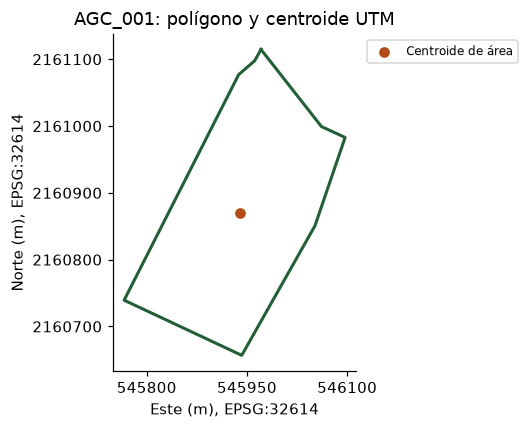

,ID_POLIGONO,AREA_HA,area_geom_ha,dif_area_pct,x_m,y_m,geom_valida_original,geom_vertices_repetidos
0,AGC_001,7.61,7.609306,-0.009117,545940.104842,2.160870e+06,True,0


In [9]:
PARCELA = "AGC_001"
meta_uno = meta.loc[meta.ID_POLIGONO.eq(PARCELA)].copy()
geom_uno = {PARCELA: geoms[PARCELA]}
geometria_utm = geo02.proyectar_geometrias(geom_uno, crs_geoms, 32614)[PARCELA]

def dibujar_borde(ax, geometria, **opciones):
    partes = [geometria] if geometria.geom_type == "Polygon" else list(geometria.geoms)
    for parte in partes:
        ax.plot(*parte.exterior.xy, **opciones)
        for anillo in parte.interiors:
            ax.plot(*anillo.xy, **opciones)

fig, ax = plt.subplots(figsize=(6.5, 4))
dibujar_borde(ax, geometria_utm, color="#225f37", linewidth=2)
ax.scatter([geometria_utm.centroid.x], [geometria_utm.centroid.y], color="#b34b16", label="Centroide de área")
ax.set(xlabel="Este (m), EPSG:32614", ylabel="Norte (m), EPSG:32614", title="AGC_001: polígono y centroide UTM")
ax.set_aspect("equal"); ax.ticklabel_format(style="plain", useOffset=False)
ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout(); plt.show()
display(meta_uno[["ID_POLIGONO", "AREA_HA", "area_geom_ha", "dif_area_pct", "x_m", "y_m",
                  "geom_valida_original", "geom_vertices_repetidos"]].round(6))

**Resultado e interpretación.** La tabla conserva ambas áreas y explicita el CRS del
centroide. La diferencia no demuestra un error de medición ni una causa agronómica.
No reparamos polígonos, densificamos bordes ni ajustamos coordenadas a una rejilla.

## 4. Ubicar celdas, esquinas y centros

**Qué comprobamos.** Los 146 GeoTIFF se leen de ZIP internos en memoria. La malla
incluye CRS, dimensiones y seis coeficientes de la transformada afín: sus huellas
exactas evitan reutilizar pesos de una rejilla diferente.

Un índice de fila/columna identifica una celda, no un punto del polígono. La esquina
superior izquierda y el centro del píxel tienen coordenadas distintas. Dibujamos
ambas posiciones y las intersecciones reales de AGC_001 con elevación.

In [10]:
rasters, inventario_rasters = fuentes02.leer_rasters(zip_fuente)
assert len(rasters) == 146
mallas = inventario_rasters.drop_duplicates("huella_malla")
assert len(mallas) == 3
display(inventario_rasters.groupby("grupo").size().rename("GeoTIFF").reset_index())
display(mallas[["archivo", "epsg", "width", "height", "transform", "huella_malla"]])
matrices_clima = np.asarray(inventario_rasters.loc[
    inventario_rasters.grupo.isin(["precipitacion", "temperatura"]), "transform"
].tolist(), dtype=float)
diferencia_afin_clima = float(np.ptp(matrices_clima, axis=0).max())
print("Diferencia del origen Y entre mallas climáticas (grados):", diferencia_afin_clima)
assert np.isclose(diferencia_afin_clima, 2.980232238769531e-7, atol=1e-12, rtol=0)
archivo_elev = "Elevacion_INEGI_CEM4_120m.tif"
piezas_elev = geo02.piezas_parcela_raster(rasters[archivo_elev], geoms[PARCELA], crs_geoms)
print("Celda del centroide:", piezas_elev["celda_centroide"], "| CRS:", piezas_elev["metadata"]["epsg"])

,grupo,GeoTIFF
0,precipitacion,48
1,temperatura,96
2,topografia,2


,archivo,epsg,width,height,transform,huella_malla
0,PREC_2022_01.tif,4326,65,72,"(0.05000000074505806, 0.0, -99.94999880716205,...",eb3d15d4312f2ce45e0dc97a2f1792714c072e1a9e5288...
48,Tmax_2022_01.tif,4326,65,72,"(0.05000000074505806, 0.0, -99.94999880716205,...",286c2bf16262265fbc90968121a562faa52d2717edace4...
144,Elevacion_INEGI_CEM4_120m.tif,6372,2900,3362,"(120.0, 0.0, 2715840.0, 0.0, -120.0, 1053840.0)",48470580d2feb5cf2fdd8d9ea7fa1b6d71abd213978636...


Diferencia del origen Y entre mallas climáticas (grados): 2.980232238769531e-07


Celda del centroide: (1761, 1198) | CRS: 6372


**De una fila/columna al cuadrado que intersectamos.** Con la afín
`(a, b, c, d, e, f)`, **x = a·col + b·fila + c** e
**y = d·col + e·fila + f**. La esquina usa enteros; el centro suma 0.5 a ambos
índices. Construimos las cuatro esquinas de una celda real de elevación y su
intersección con AGC_001, sin desplazar la malla ni redondear coordenadas.
Esta topografía usa EPSG:6372 en metros; clima requiere otra proyección de área.

In [11]:
pieza_ejemplo = piezas_elev["piezas"][0]
fila_pixel, col_pixel = pieza_ejemplo["fila"], pieza_ejemplo["col"]
a, b, c, d, e, f = piezas_elev["metadata"]["transform"]

def coordenada_visible(columna, fila):
    return a * columna + b * fila + c, d * columna + e * fila + f

esquinas_manuales = [coordenada_visible(col, fil) for col, fil in [
    (col_pixel, fila_pixel), (col_pixel + 1, fila_pixel),
    (col_pixel + 1, fila_pixel + 1), (col_pixel, fila_pixel + 1),
]]
pixel_manual = Polygon(esquinas_manuales)
al_crs_raster = Transformer.from_crs(crs_geoms, piezas_elev["metadata"]["crs_wkt"],
                                    always_xy=True).transform
parcela_en_raster = transformar_geometria(al_crs_raster, geoms[PARCELA])
interseccion_manual = parcela_en_raster.intersection(pixel_manual)
assert not interseccion_manual.is_empty and interseccion_manual.area > 0
np.testing.assert_allclose(esquinas_manuales, pieza_ejemplo["esquinas"], atol=1e-8, rtol=0)
np.testing.assert_allclose(coordenada_visible(col_pixel + .5, fila_pixel + .5),
                           pieza_ejemplo["centro"], atol=1e-8, rtol=0)
np.testing.assert_allclose(interseccion_manual.area, pieza_ejemplo["area_peso"], atol=1e-8, rtol=0)
display(pd.DataFrame(esquinas_manuales, columns=["x esquina (m)", "y esquina (m)"]))
print("Área del píxel (m²):", pixel_manual.area,
      "| Solo su intersección con la parcela (m²):", interseccion_manual.area)

,x esquina (m),y esquina (m)
0,2859600.0,842760.0
1,2859720.0,842760.0
2,2859720.0,842640.0
3,2859600.0,842640.0


Área del píxel (m²): 14400.0 | Solo su intersección con la parcela (m²): 2511.2582965936717


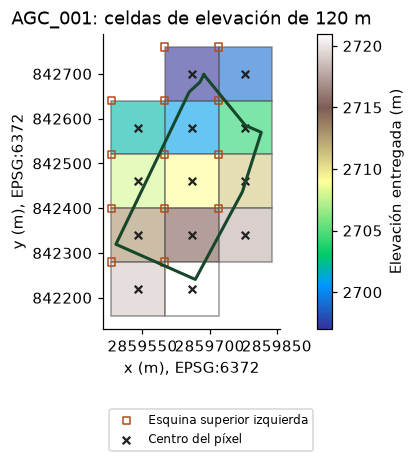

,fila,col,valor,valido,area_peso,peso_valido_normalizado
0,1759,1198,2697.0,True,2511.258297,0.033180
1,1759,1199,2699.0,True,128.715312,0.001701
2,1760,1197,2702.0,True,172.400625,0.002278
3,1760,1198,2701.0,True,12309.640839,0.162641
4,1760,1199,2704.0,True,7565.188185,0.099955
5,1761,1197,2708.0,True,5008.824789,0.066179
6,1761,1198,2709.0,True,14400.000000,0.190260
7,1761,1199,2711.0,True,7114.027747,0.093994
8,1762,1197,2713.0,True,9801.632843,0.129504
9,1762,1198,2715.0,True,13502.475224,0.178402


In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
valores_validos = [p["valor"] for p in piezas_elev["piezas"] if p["valido"]]
norma = Normalize(min(valores_validos), max(valores_validos))
for numero, pieza in enumerate(piezas_elev["piezas"]):
    color = plt.cm.terrain(norma(pieza["valor"])) if pieza["valido"] else "#d4d4d4"
    ax.add_patch(ParchePoligono(np.asarray(pieza["pixel"].exterior.coords),
                                facecolor=color, edgecolor="#555555", alpha=.6))
    ax.scatter(*pieza["esquina_ul"], marker="s", s=22, facecolors="none", edgecolors="#b34b16",
               label="Esquina superior izquierda" if numero == 0 else None)
    ax.scatter(*pieza["centro"], marker="x", s=24, color="#222222",
               label="Centro del píxel" if numero == 0 else None)
dibujar_borde(ax, piezas_elev["geometria_raster"], color="#17472a", linewidth=2)
ax.set_aspect("equal"); ax.autoscale_view(); ax.ticklabel_format(style="plain", useOffset=False)
ax.set(xlabel="x (m), EPSG:6372", ylabel="y (m), EPSG:6372", title="AGC_001: celdas de elevación de 120 m")
ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -.25))
fig.colorbar(ScalarMappable(norm=norma, cmap="terrain"), ax=ax, label="Elevación entregada (m)")
fig.tight_layout(); plt.show()
display(pd.DataFrame([{k: pieza[k] for k in ["fila", "col", "valor", "valido", "area_peso",
                                           "peso_valido_normalizado"]}
                      for pieza in piezas_elev["piezas"]]).round(6))

**Resultado y decisión.** Lluvia y temperatura tienen dos mallas distintas;
elevación y pendiente comparten la misma malla EPSG:6372. El origen Y de las
mallas climáticas difiere aproximadamente **2.98×10⁻⁷ grados**. La caché se identifica por
malla y geometrías. Contar varios píxeles no aumenta el número de parcelas ni etiquetas.

## 5. Conservar sensor, promedio de parcela y píxel extremo

**Qué comprobamos y cómo.** Reconstruimos para AGC_001 los resúmenes por captura
contrastados con el aporte de **Andrea el 21/09/2026**. Sentinel-2 y Planet aportan
NDVI en series separadas; Landsat aporta VI6T, cuya definición y escala son distintas.
La media temporal usa `*_promedio`; el píxel extremo usa `*_max` o `*_min`.

Los índices y sus resúmenes espaciales **ya vienen calculados en los CSV**:
no tenemos aquí las bandas para volver a calcular NDVI. Nuestra operación consiste
en seleccionar capturas de una parcela/sensor/ventana y resumirlas en el tiempo.

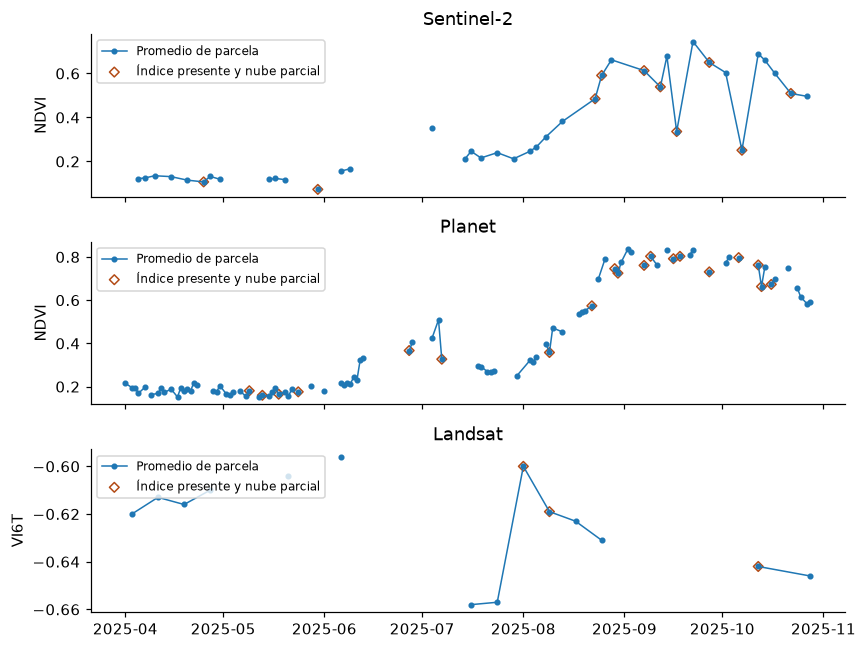

,sensor,índice,media_por_captura,pico_promedio,píxel_máximo,capturas_usadas,filas_ventana,hueco_máximo_días
0,Sentinel-2,NDVI,0.338325,0.745,0.843,40,50,25.0
1,Planet,NDVI,0.402093,0.836,0.993,97,136,14.0
2,Landsat,VI6T,-0.623929,-0.596,-0.577,14,26,48.0


,FECHA,ndvi_promedio,ndvi_max,porcentaje_nubosidad
43111,2025-10-21,0.749,0.993,0.0


In [13]:
basico_uno = basico.loc[basico.ID_POLIGONO.eq(PARCELA)].copy()
pro_uno = pro.loc[pro.ID_POLIGONO.eq(PARCELA)].copy()
ciclo_uno, historico_uno, post_uno = sat02.construir_satelite(basico_uno, pro_uno, [PARCELA], CONFIG)
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
filas_sat = []
for ax, sensor, tabla, indice, nombre in [
    (axes[0], "S2", basico_uno, "ndvi", "Sentinel-2"),
    (axes[1], "PL", pro_uno, "ndvi", "Planet"),
    (axes[2], "LS", basico_uno, "vi6t", "Landsat"),
]:
    observaciones = tabla.loc[tabla.sensor.eq(nombre) & tabla.FECHA.between(
        CONFIG["ventana_objetivo"]["inicio"], CONFIG["ventana_objetivo"]["fin"]
    )].sort_values("FECHA")
    ax.plot(observaciones.FECHA, observaciones[f"{indice}_promedio"], ".-", linewidth=1, label="Promedio de parcela")
    parcial = observaciones.loc[observaciones.porcentaje_nubosidad.gt(0)
                                 & observaciones[f"{indice}_promedio"].notna()]
    ax.scatter(parcial.FECHA, parcial[f"{indice}_promedio"], marker="D", s=20,
               facecolors="none", edgecolors="#b34b16", label="Índice presente y nube parcial")
    ax.set(ylabel=indice.upper(), title=nombre); ax.legend(fontsize=8, loc="upper left")
    p = f"C_{sensor}_{indice}"
    q = f"C_{sensor}_q"
    row = ciclo_uno.loc[PARCELA]
    filas_sat.append({"sensor": nombre, "índice": indice.upper(), "media_por_captura": row[p + "_media"],
                      "pico_promedio": row[p + "_pico_prom"], "píxel_máximo": row[p + "_pixmax"],
                      "capturas_usadas": int(row[p + "_n"]), "filas_ventana": int(row[q + "_filas_ventana"]),
                      "hueco_máximo_días": row[q + "_hueco_max_dias"]})
fig.tight_layout(); plt.show()
display(pd.DataFrame(filas_sat).round(6))
assert ciclo_uno.loc[PARCELA, "C_PL_ndvi_pixmax"] == .993
assert ciclo_uno.loc[PARCELA, "C_PL_ndvi_pico_prom"] == .836
extremo = pro_uno.loc[pro_uno.FECHA.eq(pd.Timestamp("2025-10-21")),
                      ["FECHA", "ndvi_promedio", "ndvi_max", "porcentaje_nubosidad"]]
display(extremo)
assert extremo.ndvi_max.eq(.993).all() and extremo.porcentaje_nubosidad.eq(0).all()

**Abrir el resumen: qué filas entraron y qué operación produjo la columna.**
Filtramos Planet, AGC_001 y abril–octubre. La receta exige NDVI presente y no
establece umbral de nubosidad (`None`); una nube ausente no se convierte en cero.
Sobre esas filas, calculamos media, mediana, pico del promedio y máximo de
`ndvi_max`. Los comparamos con `construir_satelite`, no con una etiqueta de rendimiento.

In [14]:
inicio_ciclo = pd.Timestamp(CONFIG["ventana_objetivo"]["inicio"])
fin_ciclo = pd.Timestamp(CONFIG["ventana_objetivo"]["fin"])
planet_ventana = pro_uno.loc[pro_uno.sensor.eq("Planet") &
                            pro_uno.FECHA.between(inicio_ciclo, fin_ciclo)].sort_values("FECHA")
umbral_nube_planet = CONFIG["nubosidad_max_por_sensor"]["PL"]
planet_admitidas = planet_ventana.copy()
if umbral_nube_planet is not None:
    planet_admitidas = planet_admitidas.loc[planet_admitidas.porcentaje_nubosidad.le(umbral_nube_planet)]
planet_ndvi = planet_admitidas.dropna(subset=["ndvi_promedio"]).copy()
fila_pico = planet_ndvi.loc[planet_ndvi.ndvi_promedio.idxmax()]
stats_manuales = {
    "C_PL_ndvi_media": planet_ndvi.ndvi_promedio.mean(),
    "C_PL_ndvi_mediana": planet_ndvi.ndvi_promedio.median(),
    "C_PL_ndvi_pico_prom": planet_ndvi.ndvi_promedio.max(),
    "C_PL_ndvi_pixmax": planet_ndvi.ndvi_max.max(),
    "C_PL_ndvi_std_media": planet_ndvi.ndvi_std.mean(),
    "C_PL_ndvi_n": len(planet_ndvi),
}
contraste_sat_visible = pd.DataFrame([
    {"columna": nombre, "cálculo visible": valor, "motor": ciclo_uno.loc[PARCELA, nombre]}
    for nombre, valor in stats_manuales.items()
])
np.testing.assert_allclose(contraste_sat_visible["cálculo visible"],
                           contraste_sat_visible.motor, atol=1e-12, rtol=0)
display(planet_ndvi[["FECHA", "ndvi_promedio", "ndvi_max", "ndvi_std", "porcentaje_nubosidad"]].head(6))
display(contraste_sat_visible.round(6))
print("Pico del promedio:", fila_pico.FECHA.date(), "| Capturas usadas:", len(planet_ndvi))
print("STD temporal, solo diagnóstico:", planet_ndvi.ndvi_promedio.std(ddof=1))

,FECHA,ndvi_promedio,ndvi_max,ndvi_std,porcentaje_nubosidad
43082,2025-04-01,0.215,0.404,0.028,0.0
43086,2025-04-03,0.196,0.349,0.028,0.0
43088,2025-04-04,0.196,0.352,0.028,0.0
43084,2025-04-05,0.169,0.358,0.030,0.0
43081,2025-04-07,0.197,0.335,0.028,0.0
43080,2025-04-09,0.163,0.349,0.032,0.0


,columna,cálculo visible,motor
0,C_PL_ndvi_media,0.402093,0.402093
1,C_PL_ndvi_mediana,0.293000,0.293000
2,C_PL_ndvi_pico_prom,0.836000,0.836000
3,C_PL_ndvi_pixmax,0.993000,0.993000
4,C_PL_ndvi_std_media,0.047278,0.047278
5,C_PL_ndvi_n,97.000000,97.000000


Pico del promedio: 2025-09-02 | Capturas usadas: 97
STD temporal, solo diagnóstico: 0.24797585074266082


**Una regla de calidad también necesita denominador.** En esta reconstrucción el
LAI negativo se conserva, no se recorta ni se imputa. Su media usa LAI presente.
La bandera `C_S2_q_lai_frac_neg` es distinta: divide capturas con LAI negativo
entre capturas Sentinel admitidas **con NDVI presente**, el índice de referencia.
Ese denominador histórico incluye una eventual ausencia de LAI; no se cambia aquí.

In [15]:
s2_ventana = basico_uno.loc[basico_uno.sensor.eq("Sentinel-2") &
                           basico_uno.FECHA.between(inicio_ciclo, fin_ciclo)].copy()
umbral_nube_s2 = CONFIG["nubosidad_max_por_sensor"]["S2"]
s2_admitidas = s2_ventana.copy()
if umbral_nube_s2 is not None:
    s2_admitidas = s2_admitidas.loc[s2_admitidas.porcentaje_nubosidad.le(umbral_nube_s2)]
s2_para_bandera = s2_admitidas.dropna(subset=["ndvi_promedio"])
lai_negativos = int(s2_para_bandera.lai_promedio.lt(0).sum())
fraccion_lai_neg_manual = lai_negativos / len(s2_para_bandera) if len(s2_para_bandera) else np.nan
lai_media_manual = s2_admitidas.lai_promedio.dropna().mean()
assert CONFIG["lai_negativos"] == "conservar"
np.testing.assert_allclose(fraccion_lai_neg_manual, ciclo_uno.loc[PARCELA, "C_S2_q_lai_frac_neg"],
                           atol=1e-12, rtol=0)
np.testing.assert_allclose(lai_media_manual, ciclo_uno.loc[PARCELA, "C_S2_lai_media"], atol=1e-12, rtol=0)
display(pd.DataFrame([{"filas de la ventana": len(s2_ventana), "con NDVI presente": len(s2_para_bandera),
                       "LAI negativos para bandera": lai_negativos, "fracción negativa": fraccion_lai_neg_manual,
                       "media LAI sin recortar": lai_media_manual}]))

,filas de la ventana,con NDVI presente,LAI negativos para bandera,fracción negativa,media LAI sin recortar
0,50,40,12,0.3,0.2977


**Resultado y límite.** Planet muestra un pico del promedio de **0.836 el 2 de
septiembre** y un píxel extremo de **0.993 el 21 de octubre**. La nubosidad registrada
de esa última captura es **0 %**; no atribuimos el extremo a una nube.
`std_media` es media de la heterogeneidad intraparcela entregada por captura,
no dispersión temporal. Los índices ausentes permanecen ausentes, nunca cero.

## 6. Distinguir media por captura, media mensual e integral

**Qué comprobamos.** Un mes con más capturas pesa más en la media por captura.
Para explicar la media mensual ponderada por días, primero obtenemos una media
por mes y después ponderamos esas medias por **30, 31, 30, 31, 31, 30 y 31 días**.
El diagnóstico queda fuera de las 539 columnas: no sustituye una receta histórica.

La integral parcial de **Codex**, incorporada en la integración del 21/09/2026,
suma trapecios entre fechas reales, acepta huecos de hasta 30 días y no extrapola.
Abril–octubre contiene **214 días calendario**, pero entre sus extremos transcurren
**213 días**. Los días cubiertos por observaciones pueden ser todavía menos.

In [16]:
diagnostico_temporal, mensual_planet = sat02.diagnosticos_media_vs_tiempo(
    pro_uno, "PL", "ndvi", [PARCELA], "2025-04-01", "2025-10-31",
    nube_max=CONFIG["nubosidad_max_por_sensor"]["PL"], max_gap=CONFIG["integral_hueco_max_dias"],
)
display(mensual_planet[["ID_POLIGONO", "mes", "media", "n", "dias_mes"]].round(6))
display(diagnostico_temporal.round(6))
assert np.isclose(diagnostico_temporal.loc[PARCELA, "media_captura"], .40209278350515465, atol=1e-12, rtol=0)
assert np.isclose(diagnostico_temporal.loc[PARCELA, "media_mensual_por_dias"], .42670903877176214, atol=1e-12, rtol=0)
assert diagnostico_temporal.loc[PARCELA, "dias_integrados"] == 210
assert sat02.partial_integral(["2025-04-01", "2025-04-11", "2025-06-30"], [1., 3., 9.]) == (20., 10.)
assert sat02.partial_integral(["2025-04-01", "2025-05-01", "2025-06-01"], [1., 3., 9.]) == (60., 30.)
print("Integral sintética: el hueco de 30 días entra y el de 31 queda fuera.")

,ID_POLIGONO,mes,media,n,dias_mes
0,AGC_001,2025-04,0.187100,20,30
1,AGC_001,2025-05,0.171824,17,31
2,AGC_001,2025-06,0.267000,11,30
3,AGC_001,2025-07,0.323222,9,31
4,AGC_001,2025-08,0.537188,16,31
5,AGC_001,2025-09,0.798909,11,30
6,AGC_001,2025-10,0.700846,13,31


,media_captura,media_mensual_simple,media_mensual_por_dias,meses_con_dato,meses_esperados,n_capturas,integral,dias_integrados,media_sobre_tramos_integrados
ID_POLIGONO,,,,,,,,,
AGC_001,0.402093,0.426584,0.426709,7,7,97,89.872,210.0,0.427962


Integral sintética: el hueco de 30 días entra y el de 31 queda fuera.


**Abrir la operación temporal.** Primero agrupamos las capturas por mes y
calculamos **Σ(media mensual × días del mes) / Σ(días)**. Exigimos los siete
meses: un mes sin dato no se rellena ni se elimina para cambiar el denominador.

Después abrimos la integral: cada par de fechas aporta
**(valor anterior + valor siguiente) / 2 × días transcurridos**, solo si su
hueco es mayor que cero y no supera 30 días. La tabla muestra seis tramos;
la suma usa todos los admitidos. Promediar fechas repetidas conserva la receta.

In [17]:
meses_ciclo = pd.period_range(inicio_ciclo, fin_ciclo, freq="M")
mensual_visible = (planet_ndvi.assign(mes=planet_ndvi.FECHA.dt.to_period("M"))
                   .groupby("mes").ndvi_promedio.agg(media="mean", n="count")
                   .reindex(meses_ciclo))
mensual_visible["dias_mes"] = mensual_visible.index.days_in_month
mensual_visible["media_por_dias"] = mensual_visible.media * mensual_visible.dias_mes
media_mensual_visible = (mensual_visible.media_por_dias.sum(min_count=len(meses_ciclo))
                         / mensual_visible.dias_mes.sum())
np.testing.assert_allclose(media_mensual_visible,
                           diagnostico_temporal.loc[PARCELA, "media_mensual_por_dias"], atol=1e-12, rtol=0)
display(mensual_visible.round(6))

serie_fechas = planet_ndvi.groupby("FECHA", as_index=False).ndvi_promedio.mean()
tramos = serie_fechas.rename(columns={"FECHA": "hasta", "ndvi_promedio": "valor_hasta"})
tramos["desde"] = tramos.hasta.shift()
tramos["valor_desde"] = tramos.valor_hasta.shift()
tramos["dias"] = (tramos.hasta - tramos.desde).dt.total_seconds() / 86_400
tramos["admitido"] = tramos.dias.gt(0) & tramos.dias.le(CONFIG["integral_hueco_max_dias"])
tramos["trapecio"] = (tramos.valor_desde + tramos.valor_hasta) / 2 * tramos.dias
tramos = tramos.iloc[1:].copy()
admitidos = tramos.loc[tramos.admitido]
integral_visible = admitidos.trapecio.sum() if len(admitidos) else np.nan
dias_visibles = admitidos.dias.sum()
np.testing.assert_allclose([integral_visible, dias_visibles],
                           ciclo_uno.loc[PARCELA, ["C_PL_ndvi_integral", "C_PL_ndvi_dias_integ"]],
                           atol=1e-12, rtol=0)
display(tramos[["desde", "hasta", "valor_desde", "valor_hasta", "dias", "admitido", "trapecio"]].iloc[6:12])
display(pd.DataFrame([
    {"operación": "Media mensual × días (diagnóstico)", "cálculo visible": media_mensual_visible,
     "motor": diagnostico_temporal.loc[PARCELA, "media_mensual_por_dias"]},
    {"operación": "Integral parcial (NDVI·día)", "cálculo visible": integral_visible,
     "motor": ciclo_uno.loc[PARCELA, "C_PL_ndvi_integral"]},
    {"operación": "Días integrados", "cálculo visible": dias_visibles,
     "motor": ciclo_uno.loc[PARCELA, "C_PL_ndvi_dias_integ"]},
]).round(6))
print("Tramos admitidos:", len(admitidos), "| Primera y última captura:",
      serie_fechas.FECHA.min().date(), serie_fechas.FECHA.max().date())

,media,n,dias_mes,media_por_dias
2025-04,0.187100,20,30,5.613000
2025-05,0.171824,17,31,5.326529
2025-06,0.267000,11,30,8.010000
2025-07,0.323222,9,31,10.019889
2025-08,0.537188,16,31,16.652812
2025-09,0.798909,11,30,23.967273
2025-10,0.700846,13,31,21.726231


,desde,hasta,valor_desde,valor_hasta,dias,admitido,trapecio
7,2025-04-11,2025-04-12,0.169,0.193,1.0,True,0.181
8,2025-04-12,2025-04-13,0.193,0.173,1.0,True,0.183
9,2025-04-13,2025-04-15,0.173,0.189,2.0,True,0.362
10,2025-04-15,2025-04-17,0.189,0.152,2.0,True,0.341
11,2025-04-17,2025-04-18,0.152,0.196,1.0,True,0.174
12,2025-04-18,2025-04-19,0.196,0.178,1.0,True,0.187


,operación,cálculo visible,motor
0,Media mensual × días (diagnóstico),0.426709,0.426709
1,Integral parcial (NDVI·día),89.872000,89.872000
2,Días integrados,210.000000,210.000000


Tramos admitidos: 96 | Primera y última captura: 2025-04-01 2025-10-28


**Interpretación.** Las tres medias responden preguntas diferentes. Ni la media
mensual ni el cociente integral/días reconstruyen automáticamente el verdadero
promedio diario. La integral describe los tramos admitidos y conserva el signo del
índice; no es biomasa. Un mes ausente conserva NaN en los diagnósticos de meses.
Esta comparación de recetas no utiliza rendimiento ni decide cuál predice mejor.

## 7. Extraer clima por intersecciones de área

**Qué comprobamos y cómo.** Para cada celda intersectada, usamos el área de su
intersección con la parcela: **Σ(valor × área válida) / Σ(área válida)**.
Para clima calculamos esas áreas en EPSG:32614; NoData y máscaras se excluyen.
Extraemos los **144 registros mensuales** de AGC_001 (48 meses × tres variables)
reutilizando una caché por malla.

El control por centroide toma la celda bajo el centroide planar del polígono en el
**CRS del ráster**. No es el centroide UTM de los metadatos reproyectado después.
Precipitación se acumula sumando mm mensuales; temperaturas se promedian en °C
ponderando por días de cada mes. No se ajusta la receta con rendimiento.

In [18]:
cache_pesos = {}
clima_uno_largo = fuentes02.extraer_clima(rasters, geom_uno, crs_geoms, cache=cache_pesos)
clima_uno = fuentes02.resumir_clima(clima_uno_largo, CONFIG)
assert len(clima_uno_largo) == 144
display(clima_uno_largo.loc[clima_uno_largo.anio.eq(2025) & clima_uno_largo.mes.between(4, 10),
                            ["variable", "anio", "mes", "pond", "cent", "n_celdas", "frac_valida"]].round(6))
display(clima_uno[["clim_prec_ciclo_mm", "clim_prec_ciclo_ctrl_centroide_mm",
                   "clim_tmin_ciclo_C", "clim_tmax_ciclo_C"]].round(6))
piezas_prec = geo02.piezas_parcela_raster(rasters["PREC_2025_04.tif"], geoms[PARCELA], crs_geoms)
display(pd.DataFrame([{k: p[k] for k in ["fila", "col", "valor", "valido", "area_peso",
                                       "peso_valido_normalizado"]} for p in piezas_prec["piezas"]]))

,variable,anio,mes,pond,cent,n_celdas,frac_valida
39,prec,2025,4,23.043688,23.043688,1,1.0
40,prec,2025,5,196.236435,196.236435,1,1.0
41,prec,2025,6,360.658081,360.658081,1,1.0
42,prec,2025,7,207.626068,207.626068,1,1.0
43,prec,2025,8,166.095749,166.095749,1,1.0
44,prec,2025,9,331.623993,331.623993,1,1.0
45,prec,2025,10,75.635109,75.635109,1,1.0
87,tmax,2025,4,26.082750,26.082750,1,1.0
88,tmax,2025,5,25.510502,25.510502,1,1.0
89,tmax,2025,6,22.285015,22.285015,1,1.0


,clim_prec_ciclo_mm,clim_prec_ciclo_ctrl_centroide_mm,clim_tmin_ciclo_C,clim_tmax_ciclo_C
ID_POLIGONO,,,,
AGC_001,1360.919123,1360.919123,11.594052,23.346556


,fila,col,valor,valido,area_peso,peso_valido_normalizado
0,37,27,23.043688,True,76093.061886,1.0


**Abrir la ponderación espacial.** Un píxel que solo toca un borde no recibe
el mismo peso que otro que cubre casi toda la parcela. Usamos las áreas de las
piezas, no el área completa del píxel ni su fracción en grados cuadrados.
En AGC_001, abril de 2025 cae en una sola celda. Añadimos **AGC_051**, que cruza
dos, para ver **peso = área válida de la pieza / área válida total** y
**aporte = valor × peso**. Sumamos los aportes y contrastamos con `extraer_raster`.

Las intersecciones de lluvia están en grados: proyectamos cada pieza a UTM14N
antes de medir m². Elevación, en cambio, ya está en un CRS métrico.

Aquí las piezas vienen del motor geométrico: este es un **contraste aritmético**,
no una reimplementación independiente de toda la extracción. La sección 4 abre
una intersección; las pruebas del proyecto comprueban mallas, máscaras y caché.

In [19]:
contrastes_lluvia = []
for id_ejemplo in [PARCELA, "AGC_051"]:
    piezas_ejemplo = geo02.piezas_parcela_raster(rasters["PREC_2025_04.tif"],
                                                geoms[id_ejemplo], crs_geoms)
    piezas_validas = pd.DataFrame([
        {"celda": f"R{p['fila']}_C{p['col']}", "lluvia_mm": p["valor"],
         "area_m2": transformar_geometria(transformar_utm, p["interseccion"]).area}
        for p in piezas_ejemplo["piezas"] if p["valido"]
    ])
    np.testing.assert_allclose(piezas_validas.area_m2,
                               [p["area_peso"] for p in piezas_ejemplo["piezas"] if p["valido"]],
                               atol=1e-8, rtol=0)
    area_valida = piezas_validas.area_m2.sum()
    piezas_validas["peso"] = piezas_validas.area_m2 / area_valida
    piezas_validas["aporte_mm"] = piezas_validas.lluvia_mm * piezas_validas.peso
    lluvia_visible = piezas_validas.aporte_mm.sum()
    control_lluvia = geo02.extraer_raster(rasters["PREC_2025_04.tif"],
                                          {id_ejemplo: geoms[id_ejemplo]}, crs_geoms)[id_ejemplo]
    np.testing.assert_allclose(piezas_validas.peso.sum(), 1., atol=1e-12, rtol=0)
    np.testing.assert_allclose(lluvia_visible, control_lluvia["pond"], atol=1e-12, rtol=0)
    display(piezas_validas.assign(ID_POLIGONO=id_ejemplo).round(6))
    contrastes_lluvia.append({"ID_POLIGONO": id_ejemplo, "cálculo visible (mm)": lluvia_visible,
                              "motor (mm)": control_lluvia["pond"],
                              "centroide (mm)": control_lluvia["cent"]})
display(pd.DataFrame(contrastes_lluvia).round(6))

,celda,lluvia_mm,area_m2,peso,aporte_mm,ID_POLIGONO
0,R37_C27,23.043688,76093.061886,1.0,23.043688,AGC_001


,celda,lluvia_mm,area_m2,peso,aporte_mm,ID_POLIGONO
0,R32_C32,10.171885,75882.397485,0.682708,6.944430,AGC_051
1,R33_C32,10.115778,35266.675987,0.317292,3.209652,AGC_051


,ID_POLIGONO,cálculo visible (mm),motor (mm),centroide (mm)
0,AGC_001,23.043688,23.043688,23.043688
1,AGC_051,10.154082,10.154082,10.171885


**Por qué NoData no equivale a cero.** El siguiente ejemplo es **inventado**,
no una parcela del reto. Una pieza sin dato conserva su área para medir cobertura,
pero no entra al denominador del promedio. Poner cero inventaría lluvia conocida.
Si ninguna pieza fuera válida, la salida sería NaN, no cero.

In [20]:
ejemplo_nodata = pd.DataFrame({"valor": [10., np.nan, 30.], "area": [1., 2., 1.]})
validas_sinteticas = ejemplo_nodata.valor.notna()
area_valida_sintetica = ejemplo_nodata.loc[validas_sinteticas, "area"].sum()
media_valida_sintetica = (ejemplo_nodata.loc[validas_sinteticas, "valor"] *
                         ejemplo_nodata.loc[validas_sinteticas, "area"]).sum() / area_valida_sintetica
media_cero_erronea = (ejemplo_nodata.valor.fillna(0) * ejemplo_nodata.area).sum() / ejemplo_nodata.area.sum()
assert media_valida_sintetica == 20. and media_cero_erronea == 10.
display(ejemplo_nodata)
print("Media sobre área válida:", media_valida_sintetica,
      "| Si se inventaran ceros:", media_cero_erronea,
      "| Fracción válida:", area_valida_sintetica / ejemplo_nodata.area.sum())

,valor,area
0,10.0,1.0
1,NaN,2.0
2,30.0,1.0


Media sobre área válida: 20.0 | Si se inventaran ceros: 10.0 | Fracción válida: 0.5


**De siete meses a una variable del ciclo.** La lluvia mensual es un acumulado
en mm: **sumamos** los siete valores. La temperatura mensual es un promedio en
°C: calculamos **Σ(°C mensual × días) / 214**. Abrimos ambas operaciones para
AGC_001 y las comparamos con las columnas finales. Una ausencia mensual propaga
NaN; no quitamos meses para obtener un ciclo aparentemente completo.

In [21]:
meses_numeros = meses_ciclo.month.tolist()
clima_meses_visible = (clima_uno_largo.loc[clima_uno_largo.anio.eq(inicio_ciclo.year)
                                         & clima_uno_largo.mes.isin(meses_numeros)]
                       .pivot(index="mes", columns="variable", values="pond")
                       .reindex(meses_numeros))
clima_meses_visible["dias"] = meses_ciclo.days_in_month.to_numpy()
clima_meses_visible["tmin_por_dias"] = clima_meses_visible.tmin * clima_meses_visible.dias
lluvia_ciclo_visible = clima_meses_visible.prec.sum(min_count=len(meses_numeros))
tmin_ciclo_visible = (clima_meses_visible.tmin_por_dias.sum(min_count=len(meses_numeros))
                      / clima_meses_visible.dias.sum())
np.testing.assert_allclose([lluvia_ciclo_visible, tmin_ciclo_visible],
                           clima_uno.loc[PARCELA, ["clim_prec_ciclo_mm", "clim_tmin_ciclo_C"]].to_numpy(dtype=float),
                           atol=1e-12, rtol=0)
display(clima_meses_visible.round(6))
display(pd.DataFrame([
    {"columna": "clim_prec_ciclo_mm", "cálculo visible": lluvia_ciclo_visible,
     "motor": clima_uno.loc[PARCELA, "clim_prec_ciclo_mm"]},
    {"columna": "clim_tmin_ciclo_C", "cálculo visible": tmin_ciclo_visible,
     "motor": clima_uno.loc[PARCELA, "clim_tmin_ciclo_C"]},
]).round(6))

variable,prec,tmax,tmin,dias,tmin_por_dias
mes,,,,,
4,23.043688,26.082750,9.261271,30,277.838116
5,196.236435,25.510502,12.582640,31,390.061831
6,360.658081,22.285015,13.630742,30,408.922262
7,207.626068,22.561089,11.782447,31,365.255853
8,166.095749,22.966181,12.016998,31,372.526947
9,331.623993,22.314344,12.329562,30,369.886866
10,75.635109,21.726736,9.568876,31,296.635164


,columna,cálculo visible,motor
0,clim_prec_ciclo_mm,1360.919123,1360.919123
1,clim_tmin_ciclo_C,11.594052,11.594052


**Decisión y límite.** La lluvia ponderada queda como valor histórico y el centroide
viaja como control. Si una parcela toca una sola celda válida, ambos pueden coincidir;
eso no demuestra que coincidan en todas. La cobertura acompaña al valor y los pesos
se normalizan sobre área válida, sin tratar NoData como cero.

## 8. Extraer elevación y pendiente con cobertura

**Qué comprobamos.** Calculamos media y desviación poblacional ponderadas por área,
mínimo, máximo y rango de las celdas válidas; elevación en metros y pendiente
entregada en grados. Conservamos la cobertura histórica: área válida dividida
por área de intersecciones dentro de la malla. Los controles de cobertura respecto
del área total de parcela quedan aparte.

La receta histórica de topografía no impone cobertura ≥0.99. Usamos AGC_170 para
observar qué significa un valor zonal con muy poca cobertura y un centroide sin dato.

In [22]:
topo_uno, controles_topo_uno = fuentes02.extraer_topografia(rasters, geom_uno, crs_geoms, cache=cache_pesos)
display(controles_topo_uno[["ID_POLIGONO", "variable", "pond", "cent", "min", "max", "std",
                           "n_validos", "frac_valida", "cobertura_total"]].round(6))
archivo_pend = "Pendiente_INEGI_CEM4_120m_grados.tif"
control_170 = geo02.extraer_raster(rasters[archivo_pend], {"AGC_170": geoms["AGC_170"]},
                                  crs_geoms, cache=cache_pesos, stats=True)["AGC_170"]
display(pd.DataFrame([{"ID_POLIGONO": "AGC_170", **control_170}]).round(6))
assert np.isclose(control_170["frac_valida"], .021, atol=.001, rtol=0)
assert np.isnan(control_170["cent"]) and np.isfinite(control_170["pond"])

,ID_POLIGONO,variable,pond,cent,min,max,std,n_validos,frac_valida,cobertura_total
0,AGC_001,elev,2708.937487,2709.000000,2697.000000,2721.000000,5.658342,13,1.0,1.0
1,AGC_001,pend,3.039548,3.253469,2.620156,3.557458,0.179337,13,1.0,1.0


,ID_POLIGONO,pond,cent,frac_valida,n_celdas,celda_centroide,cobertura_total,cobertura_malla,min,max,n_validos,std
0,AGC_170,1.39108,NaN,0.020969,14,R1699_C1228,0.020969,1.0,1.175456,1.551381,2,0.185916


**Abrir media, dispersión y cobertura.** Sobre las piezas válidas de elevación
calculamos **μ = Σ(valor × área) / Σ(área)** y
**σ = √[Σ(área × (valor − μ)²) / Σ(área)]**. Es dispersión poblacional
ponderada de la superficie, no desviación temporal ni incertidumbre predictiva.
El mínimo y máximo son valores de celdas con intersección válida.
La cobertura histórica divide por las piezas dentro de la malla;
`cobertura_total` usa toda el área de parcela. No intercambiamos denominadores.

In [23]:
elev_visible = pd.DataFrame([
    {"valor": p["valor"], "area": p["interseccion"].area}
    for p in piezas_elev["piezas"] if p["valido"]
])
area_elev_valida = elev_visible.area.sum()
media_elev_visible = (elev_visible.valor * elev_visible.area).sum() / area_elev_valida
varianza_elev_visible = (elev_visible.area * (elev_visible.valor - media_elev_visible) ** 2).sum() / area_elev_valida
stats_elev_visibles = {
    "topo_elev_media_m": media_elev_visible,
    "topo_elev_std_m": np.sqrt(varianza_elev_visible),
    "topo_elev_min_m": elev_visible.valor.min(),
    "topo_elev_max_m": elev_visible.valor.max(),
    "topo_elev_rango_m": elev_visible.valor.max() - elev_visible.valor.min(),
    "topo_elev_npix": len(elev_visible),
    "topo_elev_cobertura": area_elev_valida / piezas_elev["area_malla"],
}
contraste_elev_visible = pd.DataFrame([
    {"columna": nombre, "cálculo visible": valor, "motor": topo_uno.loc[PARCELA, nombre]}
    for nombre, valor in stats_elev_visibles.items()
])
np.testing.assert_allclose(contraste_elev_visible["cálculo visible"],
                           contraste_elev_visible.motor, atol=1e-10, rtol=0)
display(contraste_elev_visible.round(6))
print("Cobertura total de elevación:", area_elev_valida / piezas_elev["area_parcela"])

,columna,cálculo visible,motor
0,topo_elev_media_m,2708.937487,2708.937487
1,topo_elev_std_m,5.658342,5.658342
2,topo_elev_min_m,2697.000000,2697.000000
3,topo_elev_max_m,2721.000000,2721.000000
4,topo_elev_rango_m,24.000000,24.000000
5,topo_elev_npix,13.000000,13.000000
6,topo_elev_cobertura,1.000000,1.000000


Cobertura total de elevación: 1.0000000000003317


**Resultado y límite.** AGC_170 tiene cobertura de pendiente cercana a **2.1 %**.
El promedio zonal existe porque hay área con dato, pero el centroide es NaN.
Un valor calculable no garantiza representar bien toda la parcela. Conservarlo
reproduce la receta; la bandera evita confundir disponibilidad con calidad suficiente.

## 9. Repetir las recetas sobre las 197 parcelas

**Qué comprobamos y cómo.** Generalizamos sin cambiar reglas ni unir por posición.
La caché distingue conjunto de geometrías y malla. La tabla base contiene
**14 metadatos + 320 satélite del ciclo + 147 históricos + 42 clima + 16 topografía**.
Incluye la clave ID; el rendimiento nunca entra en estas piezas.

La historia 2022–2024 se resume por año y sensor; no son nuevas campañas etiquetadas.
Noviembre–diciembre de 2025 sale a otra tabla: **121 estadísticas y una clave ID**.

In [24]:
ciclo, historico, postciclo = sat02.construir_satelite(basico, pro, ids, CONFIG)
clima_largo = fuentes02.extraer_clima(rasters, geoms, crs_geoms, cache=cache_pesos)
clima = fuentes02.resumir_clima(clima_largo, CONFIG)
topo, controles_topografia = fuentes02.extraer_topografia(rasters, geoms, crs_geoms, cache=cache_pesos)
tabla_base = fuentes02.ensamblar_variables(meta, ciclo, historico, clima, topo)
tabla_postciclo = postciclo.reset_index()
tabla_uno = fuentes02.ensamblar_variables(meta_uno, ciclo_uno, historico_uno, clima_uno, topo_uno)
assert tabla_base.shape == (197, 539) and tabla_base.ID_POLIGONO.is_unique
assert tabla_postciclo.shape == (197, 122) and postciclo.shape[1] == 121
assert len(clima_largo) == 197 * 144 == 28_368
assert not any("RENDIMIENTO" in c.upper() for c in tabla_base.columns)
assert not any(c.startswith("P_") for c in tabla_base.columns)
contraste_uno = fuentes02.comparar_referencia(
    tabla_uno, tabla_base.loc[tabla_base.ID_POLIGONO.eq(PARCELA)]
)
assert contraste_uno.coincide.all(), "El recorrido de una parcela difiere de la generalización."
display(pd.DataFrame({"bloque": ["Metadatos (incluye ID)", "Satélite ciclo", "Satélite histórico", "Clima", "Topografía"],
                      "columnas": [meta.shape[1], ciclo.shape[1], historico.shape[1], clima.shape[1], topo.shape[1]]}))
vista = ["ID_POLIGONO", "AREA_HA", "C_PL_ndvi_media", "C_PL_ndvi_pico_prom", "C_S2_ndvi_media",
         "clim_prec_ciclo_mm", "topo_elev_media_m", "topo_pend_cobertura"]
display(tabla_base[vista].head(6).round(6))
print("Control una parcela ↔ 197:", int(contraste_uno.coincide.sum()), "columnas coincidentes")

,bloque,columnas
0,Metadatos (incluye ID),14
1,Satélite ciclo,320
2,Satélite histórico,147
3,Clima,42
4,Topografía,16


,ID_POLIGONO,AREA_HA,C_PL_ndvi_media,C_PL_ndvi_pico_prom,C_S2_ndvi_media,clim_prec_ciclo_mm,topo_elev_media_m,topo_pend_cobertura
0,AGC_001,7.61,0.402093,0.836,0.338325,1360.919123,2708.937487,1.0
1,AGC_002,2.31,0.454918,0.835,0.402861,961.350809,2611.461295,1.0
2,AGC_003,18.68,0.463394,0.829,0.393629,1335.090225,2642.600950,1.0
3,AGC_004,8.00,0.412143,0.700,0.311049,887.946089,2564.199598,1.0
4,AGC_005,2.27,0.480924,0.871,0.396171,793.730323,2623.981209,1.0
5,AGC_006,3.84,0.408917,0.813,0.356485,793.730323,2894.133470,1.0


Control una parcela ↔ 197: 538 columnas coincidentes


**Abrir la unión: de fuentes distintas a una misma fila.** Seleccionamos una
columna de cada bloque y las unimos explícitamente por `ID_POLIGONO`, con
`validate="one_to_one"` para rechazar duplicados. No asumimos que las tablas
estén en el mismo orden. La fila reducida se compara con la tabla completa;
es una vista didáctica, no una tabla nueva para entrenar.

In [25]:
fila_visible = meta_uno[["ID_POLIGONO", "AREA_HA"]].copy()
for bloque, columna in [
    (ciclo_uno, "C_PL_ndvi_media"), (clima_uno, "clim_prec_ciclo_mm"),
    (topo_uno, "topo_elev_media_m"),
]:
    fila_visible = fila_visible.merge(bloque[[columna]].reset_index(),
                                       on="ID_POLIGONO", how="left", validate="one_to_one")
fila_completa = tabla_base.set_index("ID_POLIGONO").loc[[PARCELA], fila_visible.columns[1:]].reset_index()
pd.testing.assert_frame_equal(fila_visible, fila_completa.reset_index(drop=True), check_exact=False,
                               atol=1e-10, rtol=0)
display(fila_visible.round(6))
print("Misma clave, misma fila; en la tabla completa:", tabla_base.shape, "sin unir rendimiento.")

,ID_POLIGONO,AREA_HA,C_PL_ndvi_media,clim_prec_ciclo_mm,topo_elev_media_m
0,AGC_001,7.61,0.402093,1360.919123,2708.937487


Misma clave, misma fila; en la tabla completa: (197, 539) sin unir rendimiento.


**Decisión y límite.** La misma parcela conserva su fila al generalizar. Ningún
faltante se imputa y ningún índice se selecciona según rendimiento. Las 539
columnas incluyen clave, metadatos, controles y banderas: su tamaño no es el
número de predictores de un modelo elegido.

## 10. Explicar cada columna en el diccionario

**Qué comprobamos.** Para cada variable registramos fuente, sensor, ventana,
agregación, filtro, unidad, rol, archivo lógico y faltantes. Hay **539 entradas de
base + 121 estadísticas postciclo = 660**; no repetimos el ID en el segundo bloque.
Los nombres de archivo identifican productos lógicos, sin exportarlos por defecto.

In [26]:
CAMPOS_DICCIONARIO = ["variable", "bloque", "rol", "fuente", "sensor", "indice", "ventana",
                      "agregacion", "filtro", "unidad", "archivo", "faltantes", "origen"]
filas_diccionario = []
for archivo, tabla in [("variables_v0_197.csv", tabla_base),
                       ("postciclo_PENDIENTE_197.csv", postciclo)]:
    for columna in tabla.columns:
        registro = fuentes02.describir_variable(columna, CONFIG)
        registro.update(archivo=archivo, faltantes=int(tabla[columna].isna().sum()),
                        origen="reconstruido desde DataSet.zip (sin Excel procesado)")
        filas_diccionario.append(registro)
diccionario = pd.DataFrame(filas_diccionario, columns=CAMPOS_DICCIONARIO)
assert diccionario.shape == (660, 13) and diccionario.variable.is_unique
assert diccionario.variable.tolist() == list(tabla_base) + list(postciclo)
assert diccionario.loc[diccionario.bloque.eq("satelite_postciclo"), "rol"].eq("pendiente_admisibilidad").all()
claves_dic = ["AREA_HA", "C_PL_ndvi_media", "C_PL_ndvi_pico_prom", "C_PL_ndvi_pixmax",
              "C_PL_ndvi_integral", "C_S2_q_lai_frac_neg", "H2022_S2_ndvi_media",
              "clim_prec_ciclo_mm", "topo_pend_cobertura", "P_PL_ndvi_media"]
display(diccionario.set_index("variable").loc[claves_dic,
        ["rol", "fuente", "ventana", "agregacion", "filtro", "unidad", "faltantes"]])
display(diccionario.groupby(["bloque", "rol"]).size().rename("variables").reset_index())
display(diccionario.loc[diccionario.faltantes.gt(0), ["variable", "rol", "faltantes"]])

,rol,fuente,ventana,agregacion,filtro,unidad,faltantes
variable,,,,,,,
AREA_HA,candidata,CSV de catálogo,estática,Área entregada,,ha,0
C_PL_ndvi_media,candidata,PRO · Planet,2025-04-01..2025-10-31,media por captura de *_promedio; no pondera me...,índice presente (sin umbral de nubosidad),unidad del índice entregado,0
C_PL_ndvi_pico_prom,candidata,PRO · Planet,2025-04-01..2025-10-31,máximo de *_promedio (pico del promedio de par...,índice presente (sin umbral de nubosidad),unidad del índice entregado,0
C_PL_ndvi_pixmax,candidata,PRO · Planet,2025-04-01..2025-10-31,máximo de *_max (píxel extremo),índice presente (sin umbral de nubosidad),unidad del índice entregado,0
C_PL_ndvi_integral,candidata,PRO · Planet,2025-04-01..2025-10-31,"trapecios con días reales, hueco ≤30 d, sin ex...",índice presente (sin umbral de nubosidad),índice·día,0
C_S2_q_lai_frac_neg,bandera_calidad,BASICO · Sentinel-2,2025-04-01..2025-10-31,fracción LAI < 0 entre capturas admitidas con ...,índice presente (sin umbral de nubosidad),fracción,0
H2022_S2_ndvi_media,candidata,BASICO · Sentinel-2,2022-04..2022-10,media por captura de *_promedio; no pondera me...,índice presente (sin umbral de nubosidad),unidad del índice entregado,0
clim_prec_ciclo_mm,candidata,GeoTIFF climáticos originales,2025-04-01..2025-10-31,Suma mensual; Áreas de intersección en EPSG:32...,"Máscara, NoData y no finitos excluidos",mm,0
topo_pend_cobertura,bandera_calidad,GeoTIFF topográficos originales,estática,Área con dato válido dividida por área de inte...,"Máscara, NoData y no finitos excluidos; cobert...",fracción,0


,bloque,rol,variables
0,clima,bandera_calidad,6
1,clima,candidata,34
2,clima,control,2
3,metadatos,bandera_calidad,3
4,metadatos,candidata,1
5,metadatos,clave,1
6,metadatos,control,1
7,metadatos,metadato_excluir,2
8,metadatos,metadato_territorial,6
9,satelite_ciclo,bandera_calidad,23


,variable,rol,faltantes
538,topo_pend_ctrl_centroide_grados,control,3


**Interpretación.** La procedencia permite distinguir un cálculo reproducible de una
hipótesis predictiva. La unidad del índice conserva el valor entregado; no lo
reinterpretamos como biomasa o una medición física nueva. Las banderas y NaN viajan
con los valores. Postciclo conserva el rol de admisibilidad pendiente.

## 11. Contrastar la reconstrucción con las salidas históricas

**Qué comprobamos y por qué.** Abrimos ahora los CSV de control incrustados de la
**tabla integrada del 21/09/2026** y de su postciclo separado. Primero se verifica
tamaño y SHA-256; después se interpretan los CSV. No alimentan ninguna transformación.

Comparamos orden de columnas, IDs, textos y máscaras de faltantes. Los conteos
deben coincidir exactamente; tolerancia absoluta **10⁻⁸** para metadatos, satélite
y clima, y **10⁻⁴** para topografía, en la unidad de cada columna. Son controles de
reproducción numérica, no una evaluación predictiva.

In [27]:
referencia_base = leer_referencia("base")
referencia_postciclo = leer_referencia("postciclo")
contraste_base = fuentes02.comparar_referencia(tabla_base, referencia_base)
contraste_postciclo = fuentes02.comparar_referencia(tabla_postciclo, referencia_postciclo)
assert len(contraste_base) == 538 and len(contraste_postciclo) == 121
assert contraste_base.coincide.all(), "La base no reproduce el control histórico."
assert contraste_postciclo.coincide.all(), "El postciclo no reproduce su control histórico."
display(pd.DataFrame([
    {"producto": "Base", "filas": len(tabla_base), "columnas_con_ID": tabla_base.shape[1],
     "columnas_comparadas_sin_ID": len(contraste_base), "coinciden": int(contraste_base.coincide.sum())},
    {"producto": "Postciclo", "filas": len(tabla_postciclo), "columnas_con_ID": tabla_postciclo.shape[1],
     "columnas_comparadas_sin_ID": len(contraste_postciclo), "coinciden": int(contraste_postciclo.coincide.sum())},
]))
display(contraste_base.sort_values("diferencia_maxima", ascending=False).head(8))

,producto,filas,columnas_con_ID,columnas_comparadas_sin_ID,coinciden
0,Base,197,539,538,538
1,Postciclo,197,122,121,121


,variable,diferencia_maxima,tolerancia_absoluta,coincide
7,y_m,1.396984e-09,1.000000e-08,True
12,dif_area_pct,1.318231e-10,1.000000e-08,True
6,x_m,1.164153e-10,1.000000e-08,True
501,clim_prec_ciclo_mm,2.103206e-11,1.000000e-08,True
503,clim_prec_ciclo_dif_pond_menos_cent_mm,2.103206e-11,1.000000e-08,True
513,clim_prec_ciclo_H2024_mm,2.069100e-11,1.000000e-08,True
510,clim_prec_ciclo_H2023_mm,1.602984e-11,1.000000e-08,True
507,clim_prec_ciclo_H2022_mm,1.466560e-11,1.000000e-08,True


**Resultado y límite.** Una coincidencia muestra que se conservaron las recetas y
su resultado dentro de tolerancias explícitas. No valida la medición de rendimiento,
el significado agronómico de cada índice ni la selección de un modelo. Los controles
modernos de cobertura se conservan aparte de la base histórica reconstruida.

## 12. Cierre: una fila trazable, todavía sin modelo

**Respuesta comprobable.** Podemos seguir AGC_001 desde geometría y capturas hasta
sus variables y repetir la operación sobre 197 IDs. El diccionario explica 660
variables, las etiquetas quedan separadas y el postciclo conserva su propio producto.
La siguiente celda registra conteos y comprueba otra vez que el ZIP sigue intacto.

**Qué se estudia y qué se automatiza.** Las celdas visibles muestran unidades,
filtros, denominadores, pesos y uniones con datos concretos. Cada contraste
comprueba una operación; no certifica por sí solo todo el motor ni la validez
agronómica de la receta. Los módulos plegados permiten repetirla sobre todas las
parcelas sin ocultar esas decisiones. Estos ejemplos no agregan variables a la
base histórica ni usan rendimiento para elegir reglas.

**Siguiente pregunta — NB03:** ¿qué referencias sencillas debemos reconstruir y
cómo compararlas sobre parcelas no utilizadas para ajustarlas? La utilidad de estas
variables se estudiará mediante validación; este cuaderno no anticipa sus resultados.

In [28]:
hash_final = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
assert hash_final == hash_inicial == SHA256_DATASET
resumen_fuentes = {
    "notebook": "02_fuentes_a_variables", "fecha_adaptacion": "2026-10-07",
    "trabajo_original": "2026-09-21", "antecedente_geo": "2026-10-01",
    "verificacion_actual": "2026-10-07",
    "fecha_ejecucion_utc": FECHA_EJECUCION_UTC, "python": platform.python_version(),
    "sha256_dataset": hash_final, "bytes_dataset": int(ruta_dataset.stat().st_size),
    "parcelas": int(len(tabla_base)), "columnas_base": int(tabla_base.shape[1]),
    "columnas_postciclo": int(postciclo.shape[1]), "variables_diccionario": int(len(diccionario)),
    "etiquetas": int(len(etiquetas)), "por_predecir": int(meta.CONJUNTO.eq("PREDICCION").sum()),
    "rasteres": int(len(rasters)), "mallas": int(len(mallas)), "filas_clima": int(len(clima_largo)),
    "columnas_ciclo": int(ciclo.shape[1]), "columnas_historico": int(historico.shape[1]),
    "faltantes_base": int(tabla_base.isna().sum().sum()),
    "variables_con_faltantes": int(tabla_base.isna().any().sum()),
    "banderas_calidad_base": int(diccionario.loc[diccionario.archivo.eq("variables_v0_197.csv"), "rol"].eq("bandera_calidad").sum()),
    "agc170_cobertura_pendiente": float(control_170["frac_valida"]),
    "base_reproduce_referencia": bool(contraste_base.coincide.all()),
    "postciclo_reproduce_referencia": bool(contraste_postciclo.coincide.all()),
    "objetivos_imputados": 0, "modelos_entrenados": 0,
    "predicciones_finales_generadas": 0, "tablas_exportadas": 0,
    "archivo_original_inalterado": True,
}
zip_fuente.close()
print(json.dumps(resumen_fuentes, ensure_ascii=False, indent=2))
print("RESUMEN_FUENTES_02_JSON=" + json.dumps(resumen_fuentes, ensure_ascii=False, sort_keys=True))

{
  "notebook": "02_fuentes_a_variables",
  "fecha_adaptacion": "2026-10-07",
  "trabajo_original": "2026-09-21",
  "antecedente_geo": "2026-10-01",
  "verificacion_actual": "2026-10-07",
  "fecha_ejecucion_utc": "2026-10-08T05:33:49.139295+00:00",
  "python": "3.13.13",
  "sha256_dataset": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",
  "bytes_dataset": 29687194,
  "parcelas": 197,
  "columnas_base": 539,
  "columnas_postciclo": 121,
  "variables_diccionario": 660,
  "etiquetas": 138,
  "por_predecir": 59,
  "rasteres": 146,
  "mallas": 3,
  "filas_clima": 28368,
  "columnas_ciclo": 320,
  "columnas_historico": 147,
  "faltantes_base": 3,
  "variables_con_faltantes": 1,
  "banderas_calidad_base": 36,
  "agc170_cobertura_pendiente": 0.020968967816182727,
  "base_reproduce_referencia": true,
  "postciclo_reproduce_referencia": true,
  "objetivos_imputados": 0,
  "modelos_entrenados": 0,
  "predicciones_finales_generadas": 0,
  "tablas_exportadas": 0,
  "archivo_ori

### Fuentes y referencias — APA 7

Equipo AgroCebada. (2026, 21 de septiembre). *Tabla integrada de fuentes y
diccionario v0* [Trabajo interno]. Resúmenes de Andrea reconstruidos desde
originales, integral parcial de Codex y recetas explícitas de integración.
Las referencias históricas de salida están incrustadas con tamaño y SHA-256.

Equipo AgroCebada. (2026, 1 de octubre). *Controles de extracción espacial*
[Antecedente interno de extracción]. Identidad de mallas, caché, afín, máscaras y cobertura.
La implementación de este cuaderno se adapta y comprueba el 7 de octubre de 2026;
no constituye una nueva hipótesis.

Rasterio contributors. (s. f.). *In-memory files*.
https://rasterio.readthedocs.io/en/stable/topics/memory-files.html

Rasterio contributors. (s. f.). *Transforms*.
https://rasterio.readthedocs.io/en/stable/topics/transforms.html

pyproj contributors. (s. f.). *Transformer*.
https://pyproj4.github.io/pyproj/stable/api/transformer.html

Shapely contributors. (s. f.). *shapely.intersection*.
https://shapely.readthedocs.io/en/stable/reference/shapely.intersection.html

Las referencias de herramientas respaldan las operaciones geométricas y la lectura;
no acreditan las inferencias agronómicas ni la capacidad predictiva de una variable.